# NB0 · Exploratory Data Analysis

**Machine Learning I · Group Project 2026-27 · The Guild of Gentle Landings**

Group XX · Data Avionaries

---

### Business understanding

The Guild wants to know, **one hour after an aviation accident**, whether it is likely to have been **fatal** (at least one person died), so that support and investigation resources go where they are needed the most.

| | |
|---|---|
| **Target** | `fatal` (1 = at least one fatality, 0 = none) |
| **Prediction moment** | one hour after the accident: only what is known at that time can be used (anything from the investigation would be leakage) |
| **Metric** | F1 score of the fatal class (balances precision and recall of class 1) |

### What this notebook does

Following CRISP-DM, this is the **Data Understanding** step. We look at the data *before* touching it: distributions, missing values, odd values, and the relations between features and with the target. Every finding ends with a **decision (or question) for NB1**. This notebook does not change the data and does not train any model.

**Contents**
1. Setup
2. First look at the data
3. The target
4. Data quality: missing values, constant columns, duplicates
5. Numerical features
6. Categorical features
7. Relations with the target
8. Relations between features
9. Summary: findings and decisions for NB1

## 1. Setup

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.stats import chi2_contingency

pd.set_option("display.max_columns", 50)
sns.set_style("whitegrid")

# library versions (for reproducibility)
print("python    ", sys.version.split()[0])
print("numpy     ", np.__version__)
print("pandas    ", pd.__version__)
print("matplotlib", matplotlib.__version__)
print("seaborn   ", sns.__version__)
print("scipy     ", scipy.__version__)

python     3.13.18
numpy      2.5.3
pandas     3.0.5
matplotlib 3.11.2
seaborn    0.13.2
scipy      1.18.1


## 2. First look at the data

In [2]:
learn = pd.read_csv("learn.csv")
predict = pd.read_csv("predict.csv")

print(f"learn:   {learn.shape[0]:,} rows x {learn.shape[1]} columns")
print(f"predict: {predict.shape[0]:,} rows x {predict.shape[1]} columns")
learn.head()

learn:   16,979 rows x 42 columns
predict: 4,245 rows x 41 columns


,row_id,ev_year,ev_month,ev_country,ev_dow,ev_hour,light_cond,wx_cond_basic,sky_cond_ceil,sky_cond_nonceil,gust_ind,sky_ceil_ht,vis_sm,wx_temp,wx_temp_c,wx_dew_pt,wind_dir_deg,wind_vel_kts,gust_kts,altimeter,apt_dist,apt_elev,far_part,acft_category,homebuilt,fixed_retractable,type_fly,flt_plan_filed,second_pilot,acft_make,ifr_equipped_cert,num_eng,total_seats,acft_year,eng_type,carb_fuel_injection,eng_power,pilot_age,pilot_sex,pilot_med_certf,phase,fatal
0,A00001,2018,9,USA,Th,19.0,DAYL,VMC,NONE,CLER,T,0,10.0,59,15.0,49,38,7.0,0,30.06,0,NaN,091,air,N,FIXD,PERS,NONE,N,PIPER,0,1.0,2.0,1956.0,REC,CARB,NaN,71.0,M,CL3,Landing,0
1,A00002,2011,7,USA,Sa,17.0,DAYL,VMC,NONE,CLER,T,0,5.0,70,21.1,56,0,3.0,0,29.91,9,629.0,091,AIR,n,FIXD,INST,NONE,n,AMERICAN AVIATION,0,1.0,2.0,NaN,REC,CARB,108.0,17.0,M,CL1,Maneuvering,1
2,A00004,2013,7,USA,Su,22.0,DAYL,VMC,UNK,FEW,F,0,10.0,80,26.7,73,0,10.0,17,30.06,0,NaN,091,AIR,N,FIXD,PERS,UNK,N,LUSCOMBE,0,1.0,2.0,NaN,REC,CARB,84.0,46.0,M,CL3,Landing,0
3,A00005,2019,9,USA,Fr,0.0,DAYL,VMC,BKN,NaN,T,10208,10.0,80,26.7,33,261,6.0,0,30.07,0,NaN,091,air,n,FIXD,PERS,NONE,N,AMERICAN AVIATION,1,1.0,4.0,1976.0,REC,CARB,150.0,31.0,M,CL1,Enroute,1
4,A00006,2008,4,USA,Su,1.0,DAYL,VMC,NONE,CLER,F,0,10.0,62,16.7,36,261,13.0,18,29.90,0,3092.0,091,AIR,N,FIXD,PERS,NONE,n,CESSNA,0,1.0,4.0,NaN,REC,CARB,174.0,68.0,M,CL3,Approach,0


In [3]:
learn.info()

<class 'pandas.DataFrame'>
RangeIndex: 16979 entries, 0 to 16978
Data columns (total 42 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   row_id               16979 non-null  str    
 1   ev_year              16979 non-null  int64  
 2   ev_month             16979 non-null  int64  
 3   ev_country           16979 non-null  str    
 4   ev_dow               16979 non-null  str    
 5   ev_hour              16960 non-null  float64
 6   light_cond           16953 non-null  str    
 7   wx_cond_basic        16960 non-null  str    
 8   sky_cond_ceil        14977 non-null  str    
 9   sky_cond_nonceil     14158 non-null  str    
 10  gust_ind             16979 non-null  str    
 11  sky_ceil_ht          16979 non-null  int64  
 12  vis_sm               16258 non-null  float64
 13  wx_temp              16979 non-null  int64  
 14  wx_temp_c            16979 non-null  float64
 15  wx_dew_pt            16979 non-null  int64  
 1

In [4]:
# split the columns in numerical and categorical (row_id and the target are left out)
num_cols = learn.drop(columns=["row_id", "fatal"]).select_dtypes(include="number").columns.tolist()
cat_cols = learn.drop(columns=["row_id", "fatal"]).select_dtypes(exclude="number").columns.tolist()

print(f"{len(num_cols)} numerical:  ", num_cols)
print(f"{len(cat_cols)} categorical:", cat_cols)

20 numerical:   ['ev_year', 'ev_month', 'ev_hour', 'sky_ceil_ht', 'vis_sm', 'wx_temp', 'wx_temp_c', 'wx_dew_pt', 'wind_dir_deg', 'wind_vel_kts', 'gust_kts', 'altimeter', 'apt_dist', 'apt_elev', 'ifr_equipped_cert', 'num_eng', 'total_seats', 'acft_year', 'eng_power', 'pilot_age']
20 categorical: ['ev_country', 'ev_dow', 'light_cond', 'wx_cond_basic', 'sky_cond_ceil', 'sky_cond_nonceil', 'gust_ind', 'far_part', 'acft_category', 'homebuilt', 'fixed_retractable', 'type_fly', 'flt_plan_filed', 'second_pilot', 'acft_make', 'eng_type', 'carb_fuel_injection', 'pilot_sex', 'pilot_med_certf', 'phase']


40 features: 20 stored as numbers and 20 as text. Two things to keep in mind already:
- `ifr_equipped_cert` is stored as a number but is really a binary flag (0/1); `ev_month` and `ev_hour` are numbers but cyclical.
- `far_part` is stored as text (`091`, `137`, ...) because the codes have leading zeros. That is correct: they are codes, not quantities.

## 3. The target

fatal
0    14090
1     2889
Name: count, dtype: int64

fatal rate: 17.0%


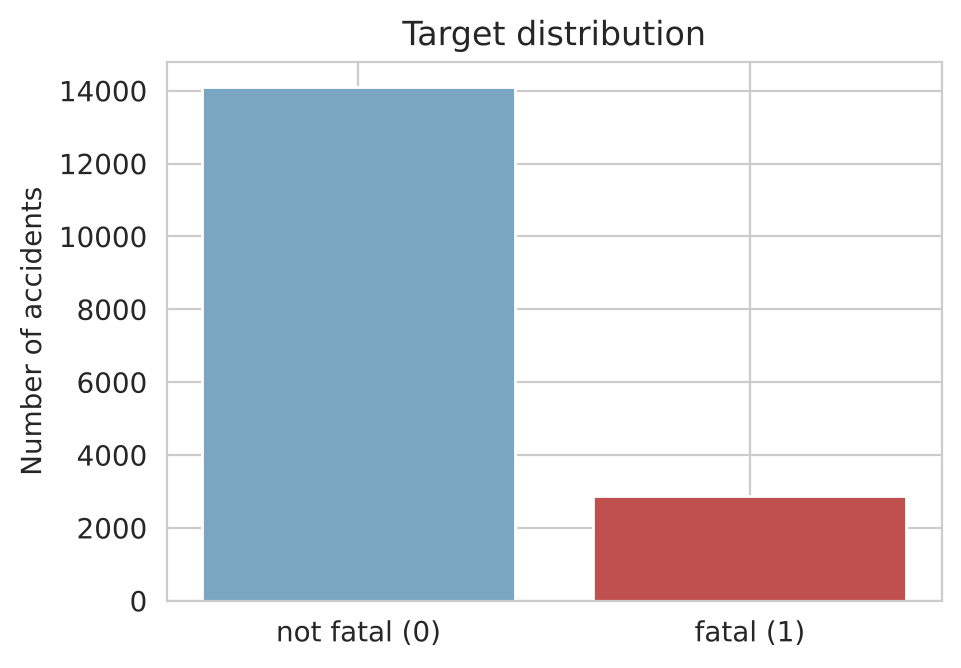

In [5]:
counts = learn["fatal"].value_counts()
print(counts)
print(f"\nfatal rate: {learn['fatal'].mean():.1%}")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["not fatal (0)", "fatal (1)"], counts.sort_index(), color=["#7aa6c2", "#c0504d"])
ax.set_title("Target distribution")
ax.set_ylabel("Number of accidents")
plt.show()

About **1 accident in 6 is fatal (17%)**: the classes are imbalanced.

**Decisions for NB1**
- Accuracy is misleading here (always predicting 0 gives 83% accuracy and F1 = 0). We use **F1 of class 1**, as required.
- All data splits must be **stratified** so that every fold keeps the 17% proportion.
- Models will probably need help with the imbalance: `class_weight="balanced"` and/or a **decision threshold** different from 0.5.

## 4. Data quality

### 4.1. Missing values

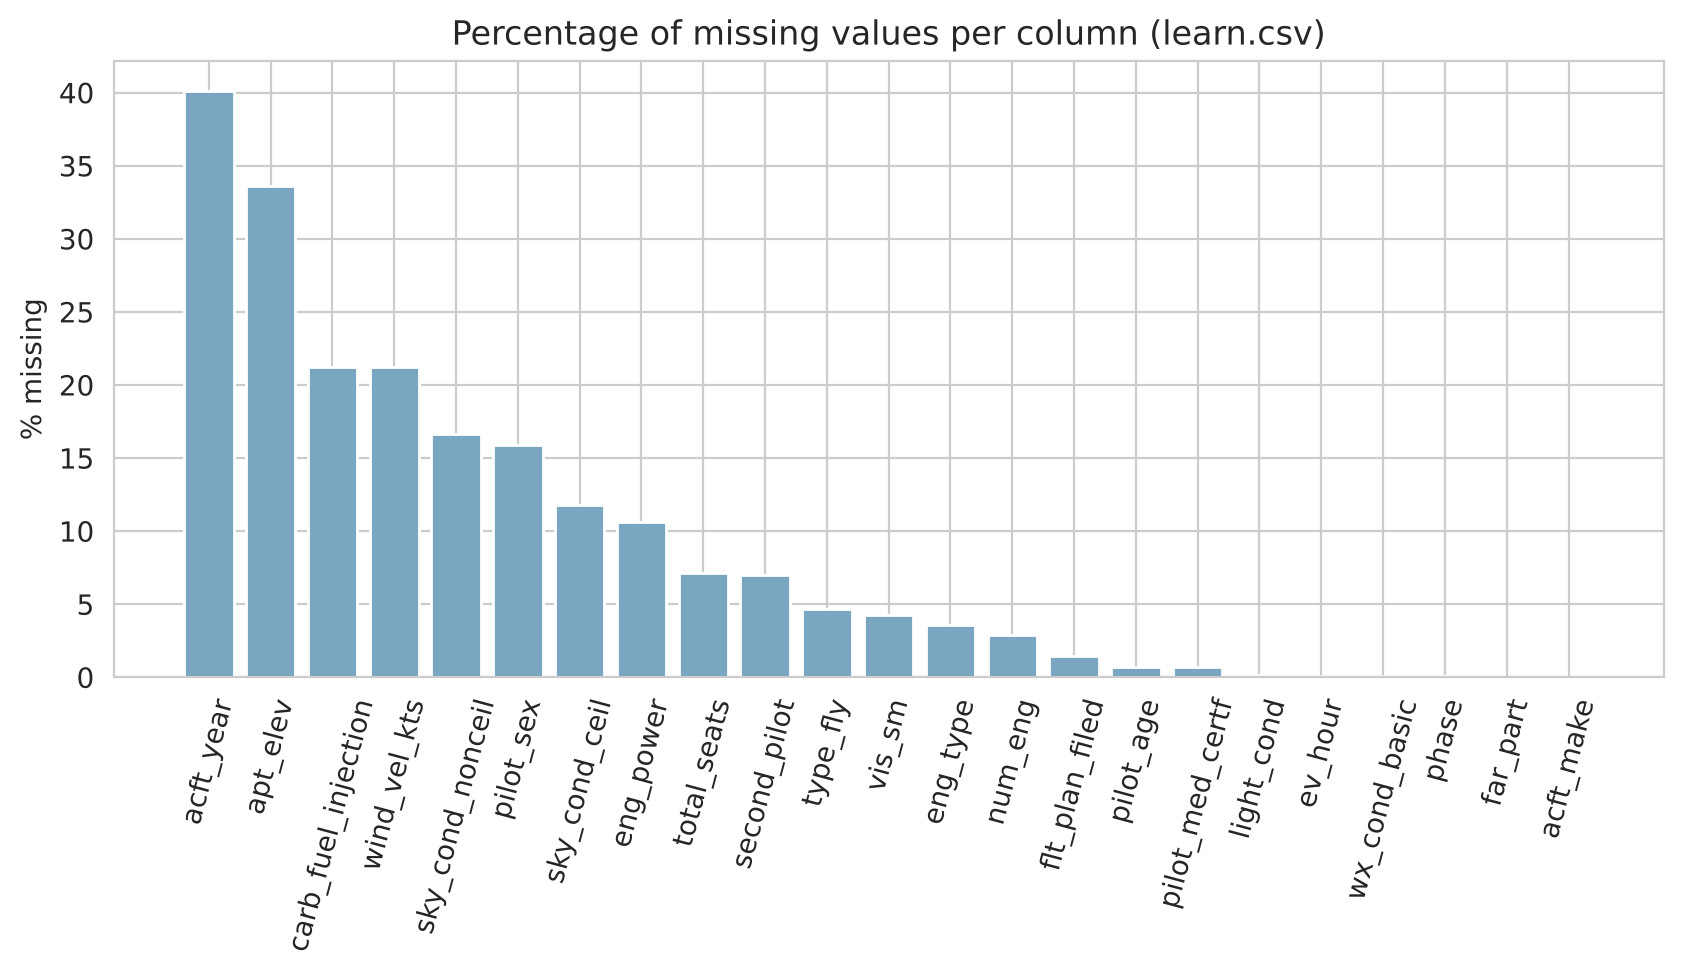

,acft_year,apt_elev,carb_fuel_injection,wind_vel_kts,sky_cond_nonceil,pilot_sex,sky_cond_ceil,eng_power,total_seats,second_pilot,type_fly,vis_sm,eng_type,num_eng,flt_plan_filed,pilot_age,pilot_med_certf,light_cond,ev_hour,wx_cond_basic,phase,far_part,acft_make
% missing,40.1,33.6,21.2,21.2,16.6,15.9,11.8,10.6,7.1,7.0,4.6,4.2,3.5,2.9,1.4,0.7,0.7,0.2,0.1,0.1,0.1,0.0,0.0


In [6]:
missing = learn.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0]

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(missing.index, missing.values * 100, color="#7aa6c2")
ax.set_title("Percentage of missing values per column (learn.csv)")
ax.set_ylabel("% missing")
plt.xticks(rotation=75)
plt.show()

missing.mul(100).round(1).to_frame("% missing").T

17 columns have missing values. `acft_year` is the worst (40%), followed by `apt_elev` (34%), `wind_vel_kts` and `carb_fuel_injection` (21%).
But empty cells are not the only form of missing data in this file: several columns use **0** or `UNK`/`NR` as a placeholder (see section 5). The real amount of missing information is higher than this chart shows.

Is the fact that a value is missing related to the target?

In [7]:
# fatal rate when the value is missing vs when it is present
rows = []
for col in missing.index:
    is_na = learn[col].isna()
    rows.append([col, is_na.mean(), learn.loc[is_na, "fatal"].mean(), learn.loc[~is_na, "fatal"].mean()])

pd.DataFrame(rows, columns=["column", "% missing", "fatal rate | missing", "fatal rate | present"]).round(3)

,column,% missing,fatal rate | missing,fatal rate | present
0,acft_year,0.401,0.161,0.176
1,apt_elev,0.336,0.217,0.146
2,carb_fuel_injection,0.212,0.152,0.175
3,wind_vel_kts,0.212,0.149,0.176
4,sky_cond_nonceil,0.166,0.224,0.159
5,pilot_sex,0.159,0.174,0.169
6,sky_cond_ceil,0.118,0.111,0.178
7,eng_power,0.106,0.184,0.169
8,total_seats,0.071,0.171,0.170
9,second_pilot,0.070,0.089,0.176


For most columns the fatal rate is similar whether the value is missing or not, but there are exceptions:
- when `second_pilot` or `vis_sm` is missing, the fatal rate drops to about 9% (vs 17-18%);
- when `apt_elev` or `sky_cond_nonceil` is missing, it goes up to 22% (vs 15-16%);
- the few rows with a missing `ev_hour`, `light_cond` or `wx_cond_basic` (19-26 rows) are fatal 38-68% of the time: probably accidents where little could be reported.

So **missingness carries information**.

**Decisions for NB1**
- Impute numerical features with the **median** (robust to the outliers we will see next), computed on the training data only, and add **missing indicators** so the model can use the fact that a value was missing.
- For categorical features, treat missing as its own category (`MISSING`) instead of filling with the mode.

### 4.2. Constant columns and duplicates

In [8]:
# number of distinct values per column
nunique = learn.drop(columns=["row_id", "fatal"]).nunique().sort_values()
print(nunique.head(8))

print("\nduplicated rows (ignoring row_id):", learn.drop(columns="row_id").duplicated().sum())
print("row_id overlap learn/predict:      ", len(set(learn["row_id"]) & set(predict["row_id"])))

ev_country             1
gust_ind               2
fixed_retractable      2
ifr_equipped_cert      2
pilot_sex              2
carb_fuel_injection    2
wx_cond_basic          3
homebuilt              4
dtype: int64

duplicated rows (ignoring row_id): 0
row_id overlap learn/predict:       0


- `ev_country` has a **single value** (`USA`) in the whole file: it tells us nothing. → **drop it**.
- No duplicated rows, and no overlap between `learn` and `predict`.

## 5. Numerical features

In [9]:
learn[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
ev_year,16979.0,2015.07,4.64,2008.0,2011.00,2015.00,2019.00,2023.00
ev_month,16979.0,6.63,2.98,1.0,4.00,7.00,9.00,12.00
ev_hour,16960.0,15.69,6.47,0.0,14.00,17.00,20.00,23.00
sky_ceil_ht,16979.0,1575.38,4524.77,0.0,0.00,0.00,0.00,241340.00
vis_sm,16258.0,10.70,52.88,0.0,10.00,10.00,10.00,5000.00
wx_temp,16979.0,63.99,32.48,-55.0,54.00,69.00,80.00,3005.00
wx_temp_c,16979.0,17.77,18.05,-48.3,12.20,20.60,26.70,1651.70
wx_dew_pt,16979.0,43.66,50.58,-39.0,29.00,46.00,61.00,3027.00
wind_dir_deg,16979.0,142.21,118.82,0.0,0.00,146.00,244.00,360.00
wind_vel_kts,13376.0,7.90,4.93,0.0,5.00,7.00,10.00,185.00


The summary table already shows several instruments lying to us. Some maximums are impossible: `wx_temp` = 3005 °F, `altimeter` = 3053 inHg, `total_seats` = 8300, `pilot_age` = 214, `vis_sm` = 5000 miles, `acft_year` = 0. Let's look at the distributions.

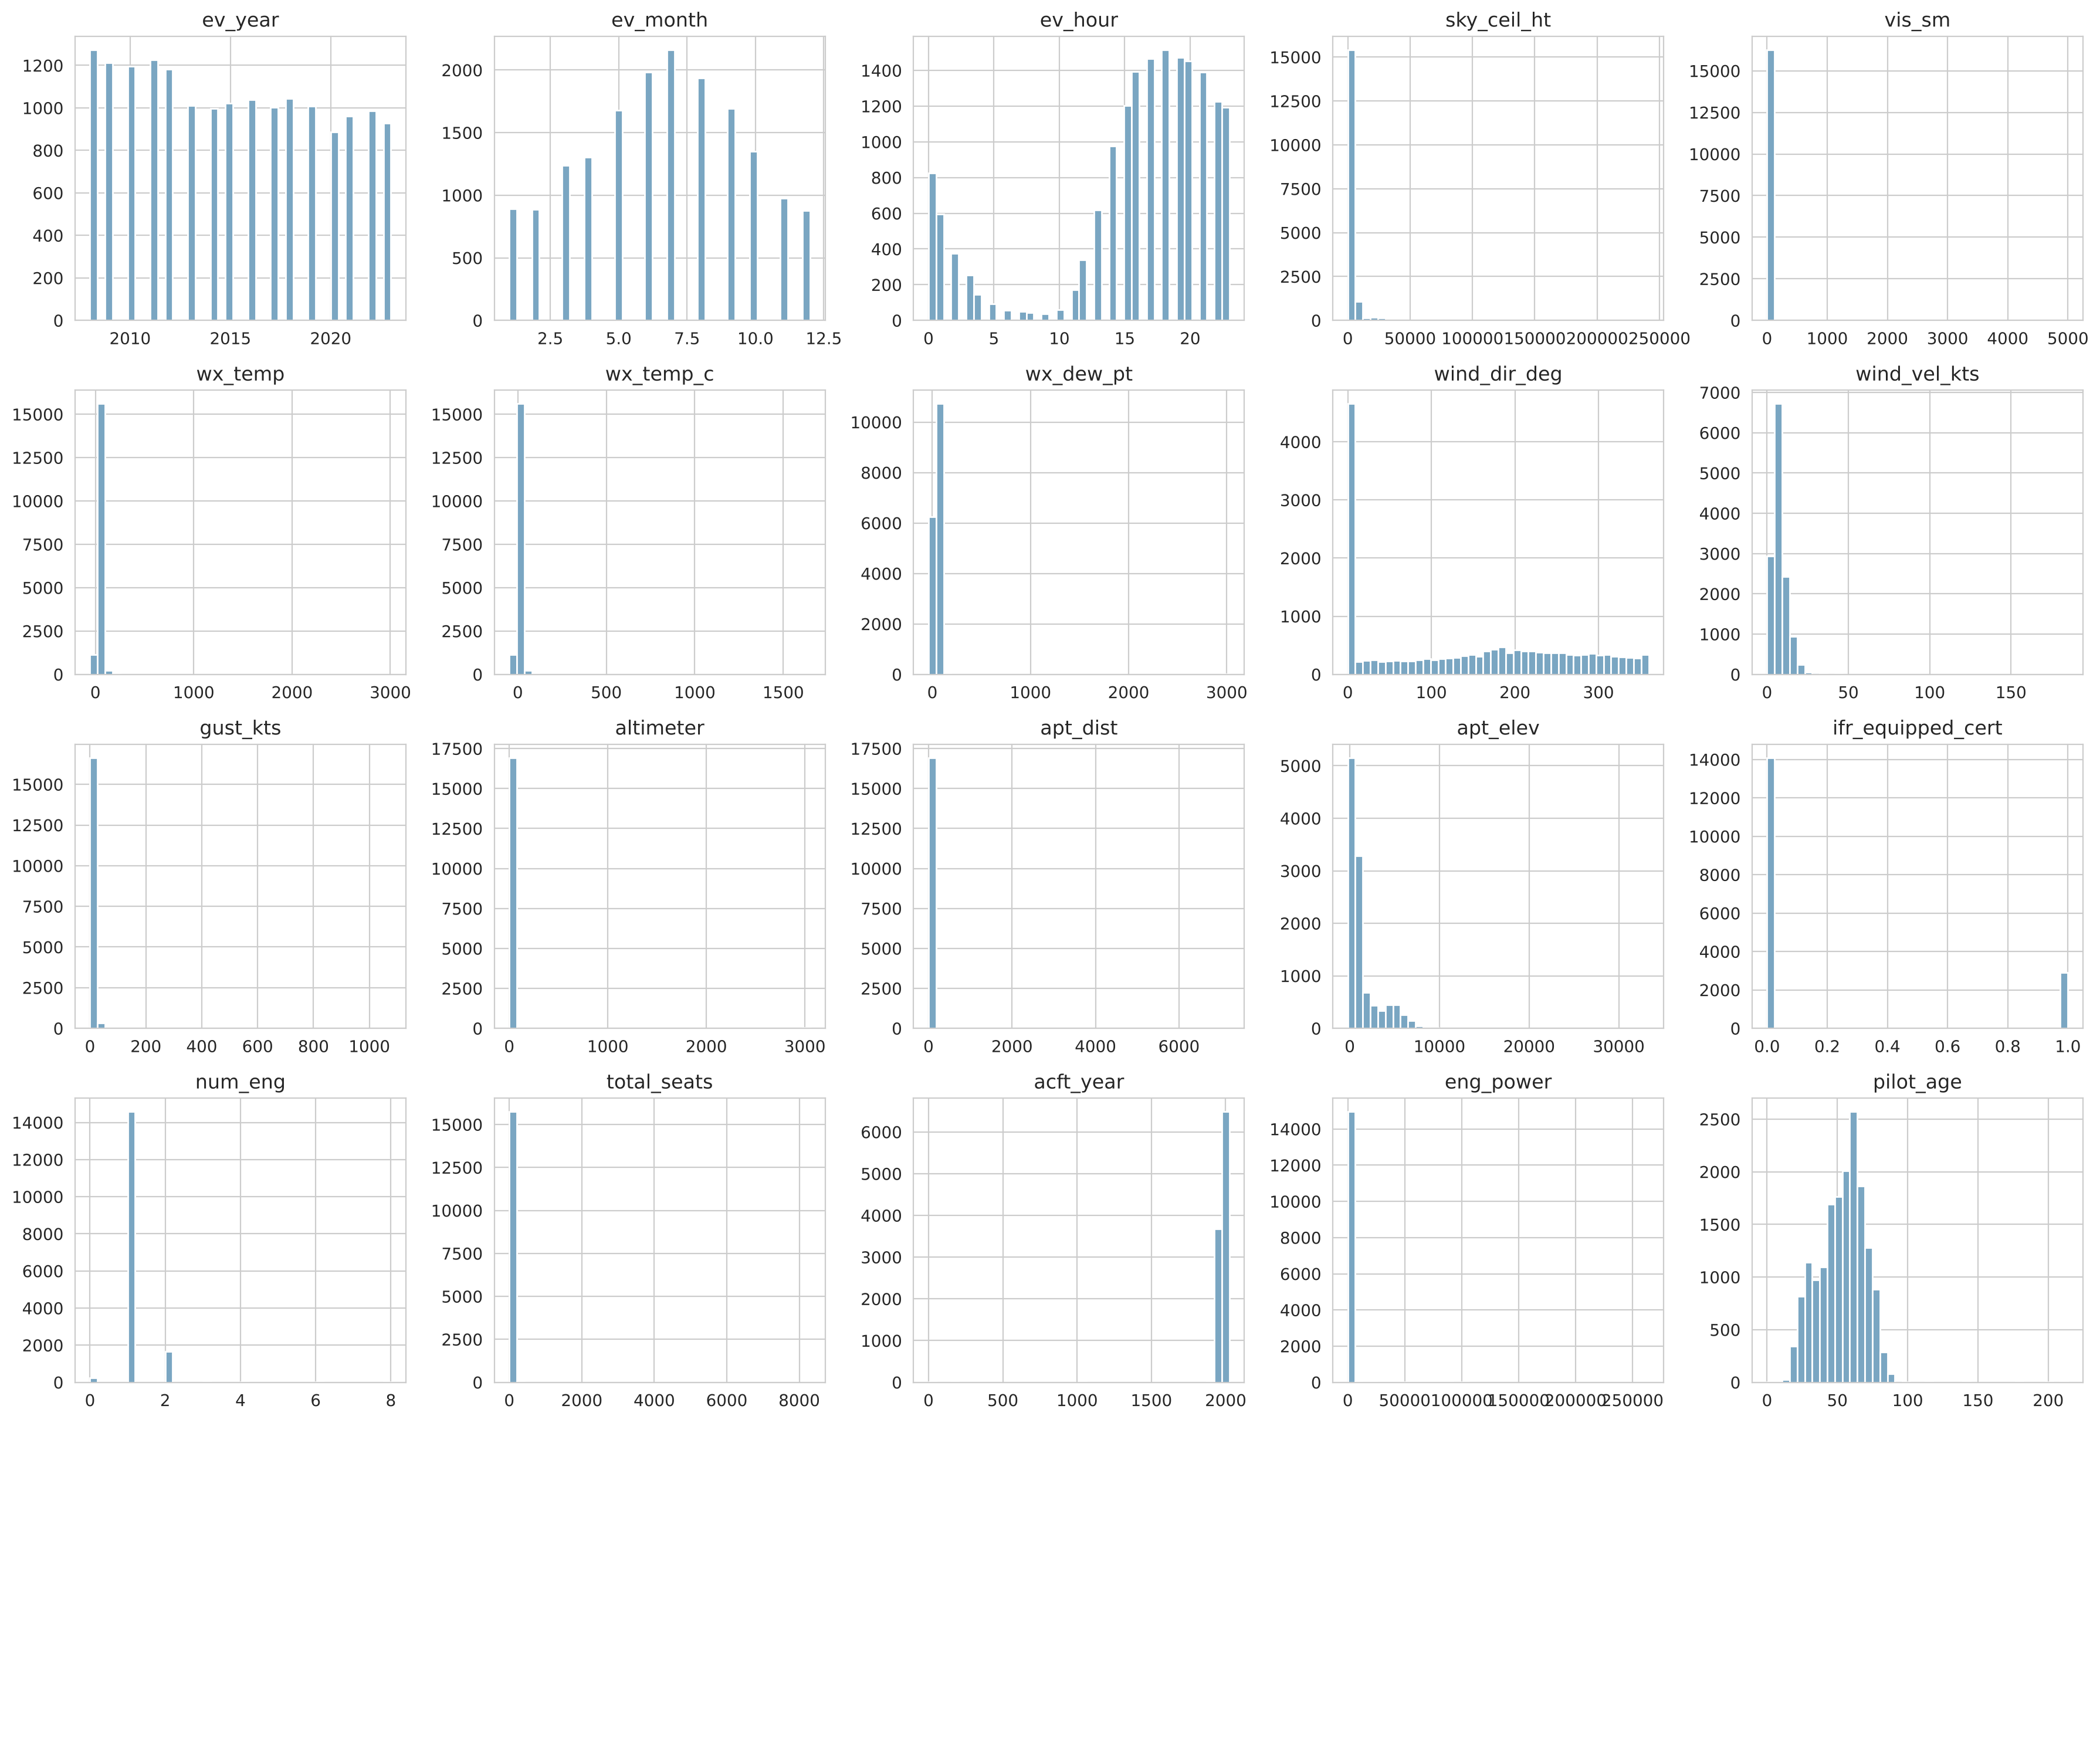

In [10]:
# histograms of every numerical feature
fig, axes = plt.subplots(5, 5, figsize=(18, 15))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    axes[i].hist(learn[col].dropna(), bins=40, color="#7aa6c2")
    axes[i].set_title(col)
for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

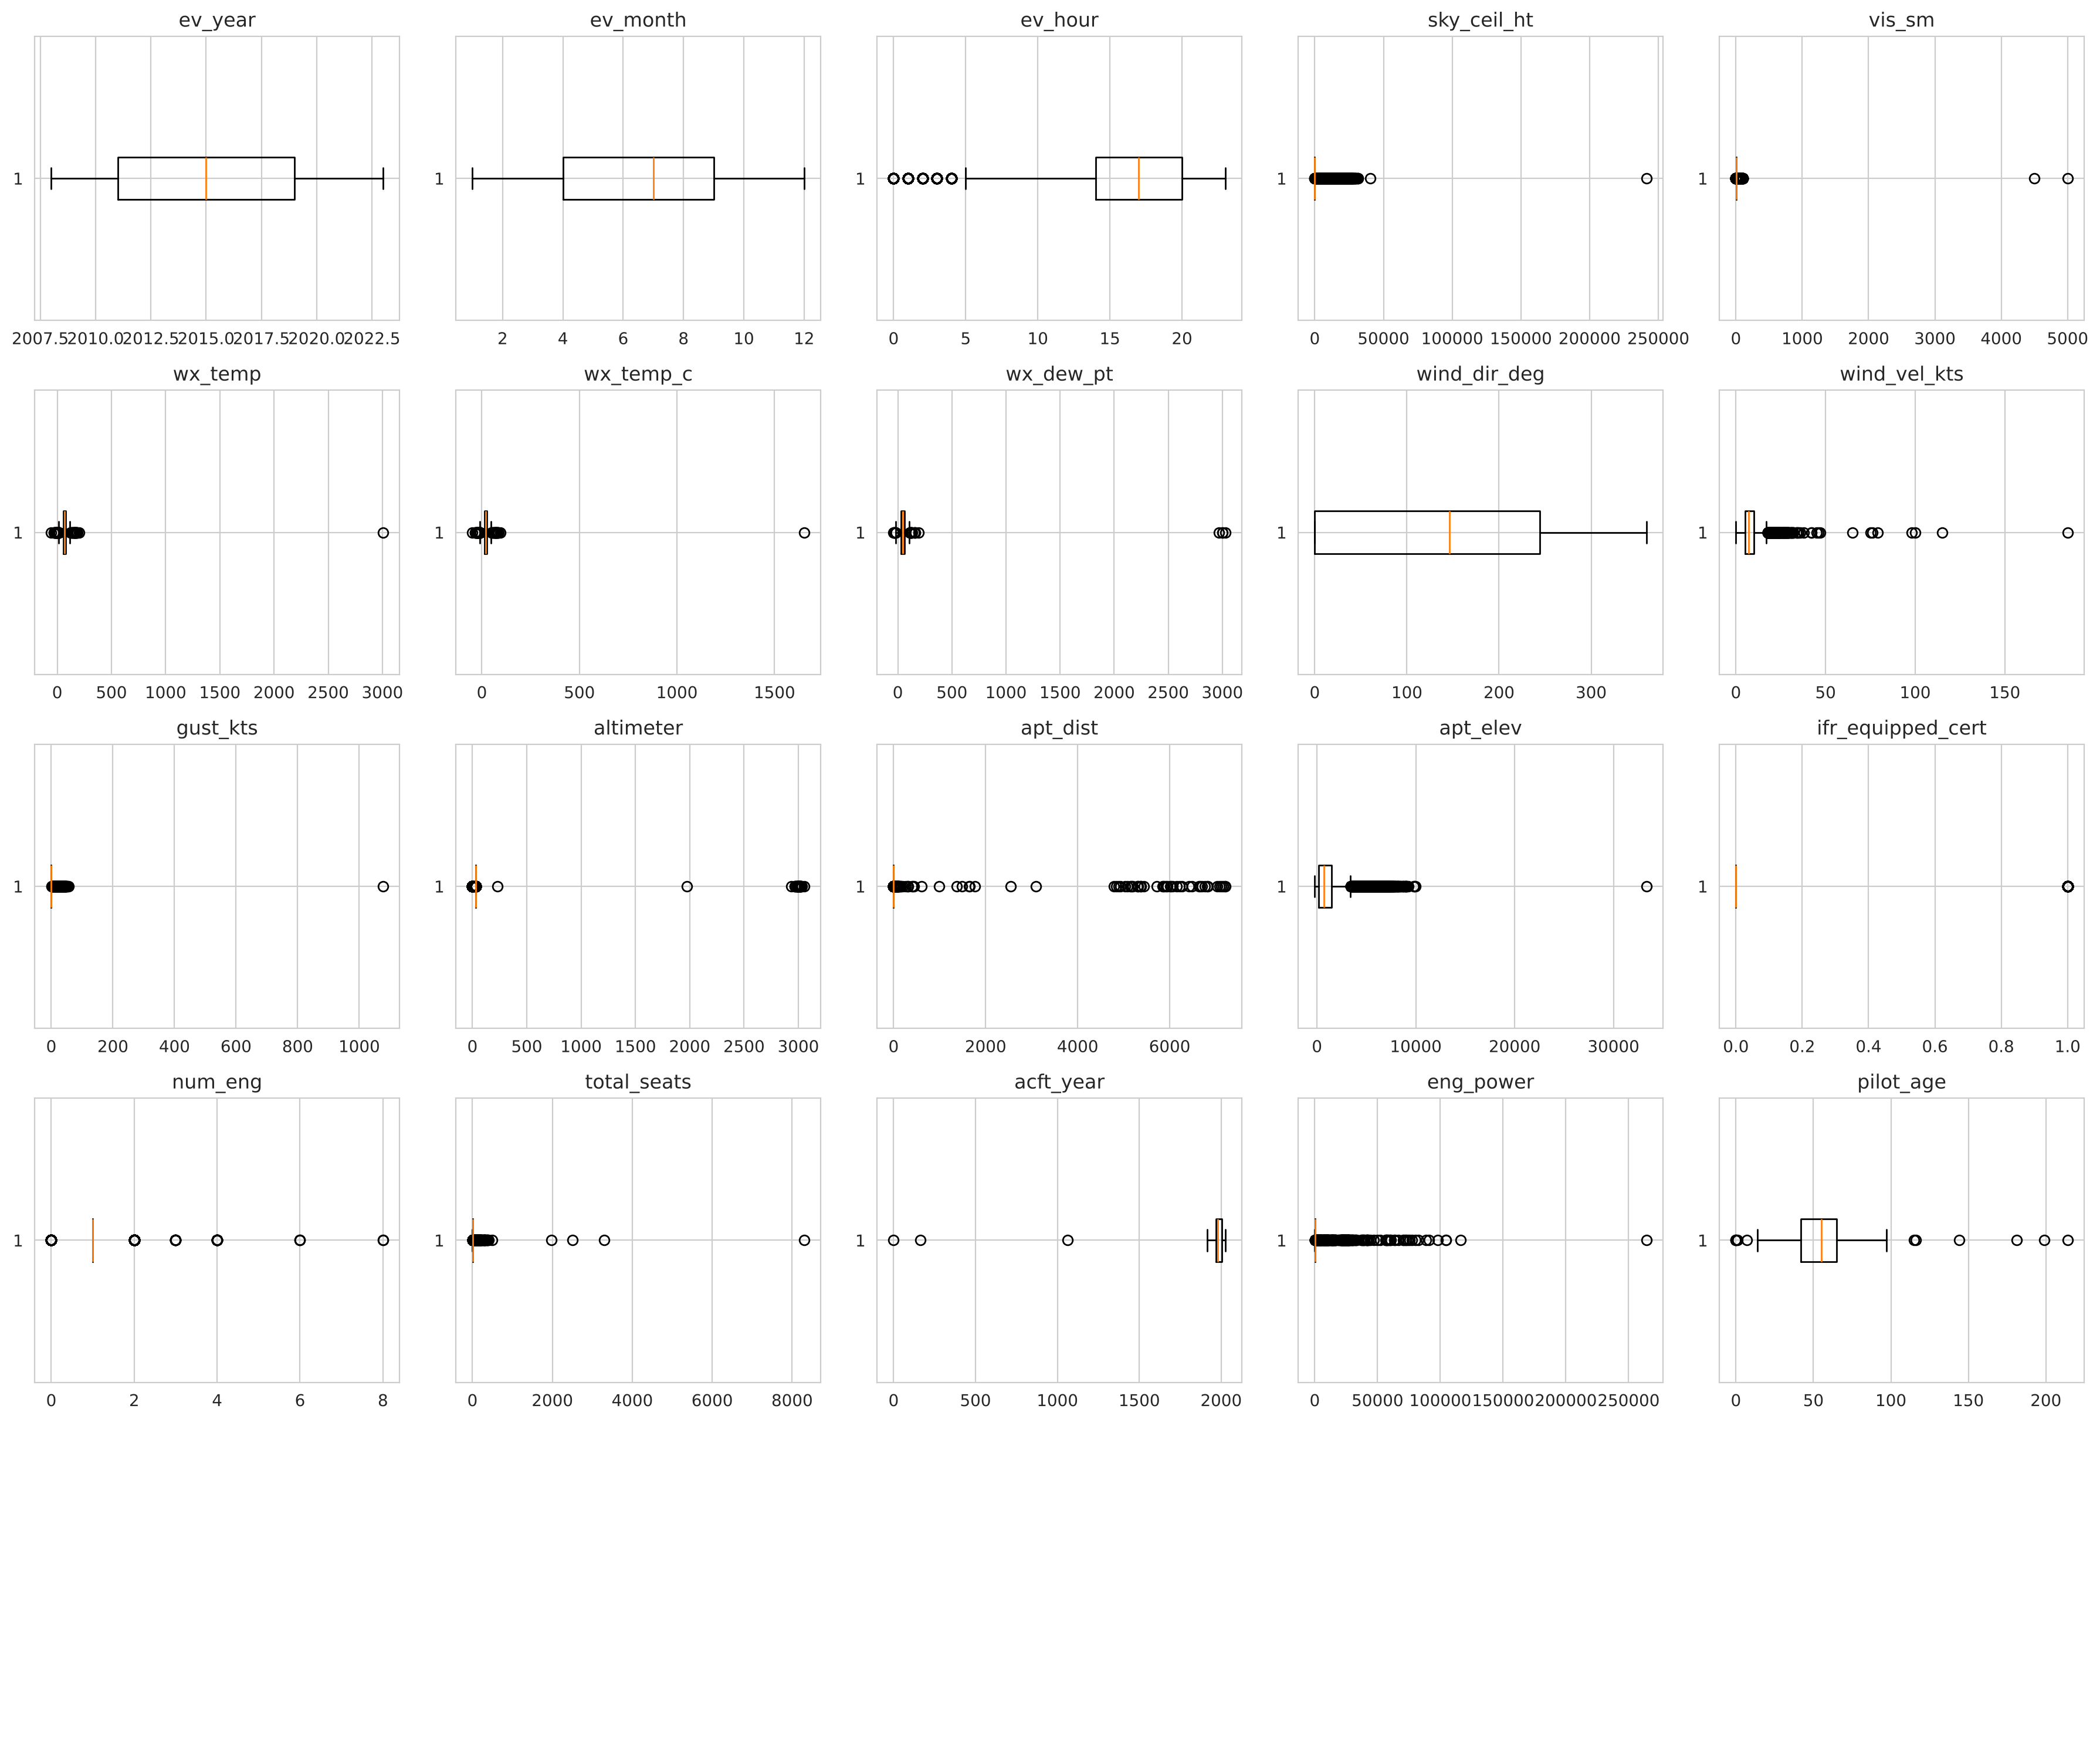

In [11]:
# boxplots, to see the outliers
fig, axes = plt.subplots(5, 5, figsize=(18, 15))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    axes[i].boxplot(learn[col].dropna(), orientation="horizontal")
    axes[i].set_title(col)
for j in range(len(num_cols), len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

Almost every distribution is squeezed into a corner by a handful of extreme values. We check the suspicious features one by one.

### 5.1. Temperature and dew point

In [12]:
# wx_temp_c is the Guild's conversion of wx_temp: is it exactly (F - 32) * 5/9?
converted = (learn["wx_temp"] - 32) * 5 / 9
print("wx_temp_c equals the conversion of wx_temp:", ((learn["wx_temp_c"] - converted).abs() < 0.06).mean())

# zeros
print("\nwx_temp == 0:                   ", (learn["wx_temp"] == 0).sum())
print("wx_temp == 0 and wx_dew_pt == 0:", ((learn["wx_temp"] == 0) & (learn["wx_dew_pt"] == 0)).sum())

# impossible values (the highest temperature ever recorded in the USA is 134 F)
print("\nwx_temp > 130 F:  ", (learn["wx_temp"] > 130).sum())
print("wx_dew_pt > 100 F:", (learn["wx_dew_pt"] > 100).sum())
print("dew point above temperature:", (learn["wx_dew_pt"] > learn["wx_temp"]).sum())

wx_temp_c equals the conversion of wx_temp: 1.0

wx_temp == 0:                    855
wx_temp == 0 and wx_dew_pt == 0: 832

wx_temp > 130 F:   31
wx_dew_pt > 100 F: 23
dew point above temperature: 268


- `wx_temp_c` is **exactly** `wx_temp` converted to Celsius in 100% of the rows: it is a **redundant column** with no new information. → **drop it**.
- 855 rows have `wx_temp` = 0 °F, and 832 of them also have dew point = 0. A temperature *and* a dew point of exactly 0 °F, mostly in summer accidents, is not weather: it is a **missing value coded as 0**. → set to NaN when both are 0.
- 31 temperatures above 130 °F (and 23 dew points above 100 °F) are physically impossible in the USA. → set to NaN.
- Dew point and temperature together tell us about humidity / fog risk: their difference (the *spread*) is a candidate **new feature**.

### 5.2. Altimeter

In [13]:
alt = learn["altimeter"]
print(pd.cut(alt, [-1, 0, 27, 32, 2800, 3200]).value_counts().sort_index())
print("\nexamples of values above 2800:", alt[alt > 2800].head(8).tolist())

altimeter
(-1, 0]          1510
(0, 27]             6
(27, 32]        15405
(32, 2800]          4
(2800, 3200]       54
Name: count, dtype: int64

examples of values above 2800: [2968.04, 2995.0, 3009.98, 3009.0, 2992.99, 3002.03, 3020.03, 2989.02]


The altimeter setting should be close to 29.92 inHg. We find three groups:
- **1,510 zeros**: no real pressure is 0 → missing value coded as 0.
- **54 values around 3000** (2968, 3010, ...): the same reading **written without the decimal point** (2992 = 29.92 inHg). This is the "unit that changes from row to row".
- A few values outside 27-32 inHg (e.g. 22, 35, 500), which are impossible at ground level.

**Decision:** divide the values above 2800 by 100, and set everything outside 27-32 inHg to NaN.

### 5.3. Engine power: horsepower or pounds of thrust?

In [14]:
learn.groupby("eng_type")["eng_power"].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
eng_type,,,,,,,,
ELEC,4.0,27.0,18.0,5.0,20.0,27.0,34.0,50.0
GTFN,1.0,3399.0,NaN,3399.0,3399.0,3399.0,3399.0,3399.0
HR,1.0,59570.0,NaN,59570.0,59570.0,59570.0,59570.0,59570.0
LR,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
NONE,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
REC,13217.0,202.0,154.0,0.0,132.0,179.0,252.0,3293.0
TF,334.0,17441.0,24197.0,0.0,3261.0,8926.0,23993.0,264190.0
TJ,87.0,9312.0,12840.0,0.0,2072.0,3424.0,10717.0,63837.0
TP,765.0,846.0,566.0,0.0,661.0,754.0,908.0,10378.0


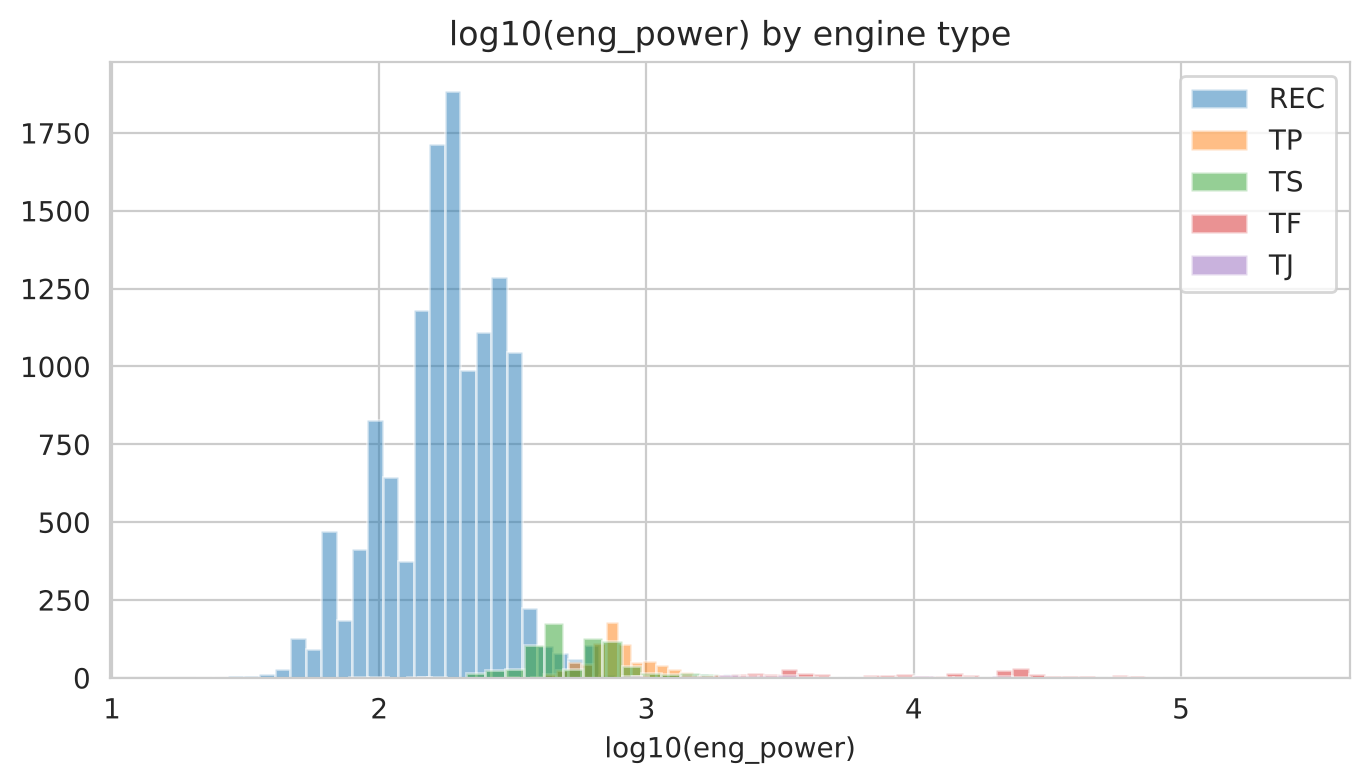

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
for t in ["REC", "TP", "TS", "TF", "TJ"]:
    values = learn.loc[learn["eng_type"] == t, "eng_power"].dropna()
    ax.hist(np.log10(values[values > 0]), bins=40, alpha=0.5, label=t)
ax.set_title("log10(eng_power) by engine type")
ax.set_xlabel("log10(eng_power)")
ax.legend()
plt.show()

As the data dictionary warns, `eng_power` mixes two **different units**: horsepower for piston (`REC`), turboprop (`TP`) and turboshaft (`TS`) engines, and **pounds of thrust** for jets (`TF`, `TJ`). A turbofan's "8,926" is not 50 times stronger than a piston's "179": the numbers are not comparable.
There are also zeros (impossible for a powered aircraft) and extreme values (75,552 HP for a turboshaft).

**Decision:** create `eng_power_hp`, keeping the power only for non-jet engines (jets get NaN, and the engine type itself tells the model it's a jet); zeros and values above 5,000 HP become NaN.

### 5.4. Wind and gusts: an instrument that lies

In [16]:
print(pd.crosstab(learn["gust_ind"], learn["gust_kts"] > 0, margins=True).rename(columns={False: "gust_kts = 0", True: "gust_kts > 0"}))

gust_kts  gust_kts = 0  gust_kts > 0    All
gust_ind                                   
F                 3429          2616   6045
T                10929             5  10934
All              14358          2621  16979


`gust_ind` should say whether there were gusts. But when `gust_ind` = **T** (true), the gust speed is 0 in 10,929 of 10,934 rows; and **all** the recorded gusts appear with `gust_ind` = **F**. The indicator is **inverted / unreliable**, and `gust_kts` already contains the same information. → **drop `gust_ind`**, and create a clean `has_gust` flag from `gust_kts > 0`.

In [17]:
print("wind_vel_kts > 100:", (learn["wind_vel_kts"] > 100).sum(), " max:", learn["wind_vel_kts"].max())
print("gust_kts > 100:    ", (learn["gust_kts"] > 100).sum(), " max:", learn["gust_kts"].max())
print("wind_dir_deg == 0: ", f"{(learn['wind_dir_deg'] == 0).mean():.1%}")
print("fatal rate by wind direction quadrant:")
print(learn.groupby(pd.cut(learn["wind_dir_deg"], [-1, 0, 90, 180, 270, 360]))["fatal"].mean().round(3))

wind_vel_kts > 100: 2  max: 185.0
gust_kts > 100:     1  max: 1077
wind_dir_deg == 0:  25.8%
fatal rate by wind direction quadrant:
wind_dir_deg
(-1, 0]       0.148
(0, 90]       0.194
(90, 180]     0.192
(180, 270]    0.165
(270, 360]    0.168
Name: fatal, dtype: float64


- Winds of 185 knots and gusts of 1,077 knots are not surface weather. → values above 100 kts become NaN.
- `wind_dir_deg` is 0 in 26% of the rows (calm or missing), and the direction alone means nothing without the runway heading: the fatal rate is flat across quadrants. → **drop `wind_dir_deg`**.

### 5.5. Visibility and cloud ceiling

In [18]:
print("vis_sm above 10:", (learn["vis_sm"] > 10).sum())
print(learn.loc[learn["vis_sm"] > 10, "vis_sm"].value_counts().head(8))

print("\nsky_ceil_ht > 0 by ceiling condition:")
print(pd.crosstab(learn["sky_cond_ceil"].fillna("NaN"), learn["sky_ceil_ht"] > 0))
print("\nsky_ceil_ht above 40,000 ft:", (learn["sky_ceil_ht"] > 40000).sum())

vis_sm above 10: 445
vis_sm
20.0     115
15.0      65
30.0      64
50.0      50
40.0      43
25.0      34
12.0      22
100.0     12
Name: count, dtype: int64

sky_ceil_ht > 0 by ceiling condition:
sky_ceil_ht    False  True 
sky_cond_ceil              
BKN               66   2508
NONE           10641     21
NaN             1987     15
OVC               30   1567
UNK               92      3
VV                18     31

sky_ceil_ht above 40,000 ft: 2


- Weather reports cap visibility at **10 statute miles** ("10 or more"). Values like 20, 50 or 5000 do not add information. → **clip at 10**.
- `sky_ceil_ht` = 0 almost always means "no ceiling" (`NONE`) rather than a cloud at ground level, so 0 is not a real height. A binary `has_ceiling` flag is a candidate feature. One value of 241,340 ft is impossible. → values above 40,000 ft become NaN.

### 5.6. Distance to the airport and airport elevation

In [19]:
print(learn["apt_dist"].describe().round(1))
print("\napt_dist == 0:", f"{(learn['apt_dist'] == 0).mean():.1%}")
print("apt_dist > 500:", (learn["apt_dist"] > 500).sum())

print("\nfatal rate by distance to the airport:")
print(learn.groupby(pd.cut(learn["apt_dist"], [-1, 0, 1, 5, 20, 500, 1e5]))["fatal"].agg(["mean", "size"]).round(3))
print("\napt_elev > 15,000 ft:", (learn["apt_elev"] > 15000).sum(), " max:", learn["apt_elev"].max())

count    16979.0
mean        17.1
std        304.3
min          0.0
25%          0.0
50%          0.0
75%          0.0
max       7208.0
Name: apt_dist, dtype: float64

apt_dist == 0: 77.3%
apt_dist > 500: 52

fatal rate by distance to the airport:
                    mean   size
apt_dist                       
(-1.0, 0.0]        0.141  13119
(0.0, 1.0]         0.225   2381
(1.0, 5.0]         0.328    856
(5.0, 20.0]        0.376    417
(20.0, 500.0]      0.364    154
(500.0, 100000.0]  0.096     52

apt_elev > 15,000 ft: 1  max: 33333.0


- 77% of the accidents happen **at the airport** (distance 0). Their fatal rate is 14%, while accidents **away from the airport** (1-20 miles) reach 33-38%. This is one of the clearest signals in the data. → create an `off_airport` flag; since the distance is very skewed, also use `log(1 + apt_dist)`.
- Distances above 500 miles to the *nearest* airport are impossible in the USA. → NaN.
- An airport at 33,333 ft does not exist (the highest US airports are around 10,000 ft). → values above 15,000 ft become NaN.

### 5.7. Aircraft year, seats and number of engines

In [20]:
print("acft_year < 1900:", (learn["acft_year"] < 1900).sum(), "->", sorted(learn.loc[learn["acft_year"] < 1900, "acft_year"].tolist()))
print("aircraft built after the accident year:", (learn["acft_year"] > learn["ev_year"]).sum())

print("\ntotal_seats == 0:", (learn["total_seats"] == 0).sum())
print("largest values of total_seats:", sorted(learn["total_seats"].dropna().unique())[-8:])

print("\nnum_eng:")
print(learn["num_eng"].value_counts().sort_index())

acft_year < 1900: 3 -> [0.0, 163.0, 1062.0]
aircraft built after the accident year: 86

total_seats == 0: 37
largest values of total_seats: [np.float64(379.0), np.float64(380.0), np.float64(400.0), np.float64(490.0), np.float64(1979.0), np.float64(2500.0), np.float64(3300.0), np.float64(8300.0)]

num_eng:
num_eng
0.0      243
1.0    14574
2.0     1646
3.0        9
4.0       17
6.0        3
8.0        2
Name: count, dtype: int64


- `acft_year` contains years 0, 163 and 1062, and **86 aircraft "built" after the accident**. These are errors. → NaN. The year itself is less useful than the **age of the aircraft at the time of the accident** (`ev_year - acft_year`). → new feature `acft_age`.
- 37 aircraft with 0 seats (someone must be flying!) and seat counts like 1979, 3300 or 8300 (the largest airliners have about 850). → 0 and values above 600 become NaN.
- `num_eng` = 0 for 243 rows: these are mostly gliders and balloons, so it is plausible. → keep.

### 5.8. Pilot age

In [21]:
print("pilot_age < 14: ", (learn["pilot_age"] < 14).sum(), sorted(learn.loc[learn["pilot_age"] < 14, "pilot_age"].tolist()))
print("pilot_age > 100:", (learn["pilot_age"] > 100).sum(), sorted(learn.loc[learn["pilot_age"] > 100, "pilot_age"].tolist()))

pilot_age < 14:  6 [0.0, 0.0, 0.0, 0.0, 1.0, 7.0]
pilot_age > 100: 6 [115.0, 116.0, 144.0, 181.0, 199.0, 214.0]


A pilot aged 0, 1 or 7, or 144, 199 and 214, is a typing error (14 is the minimum age to fly a glider solo). → values outside 14-100 become NaN.

### 5.9. Hour of the accident: local time?

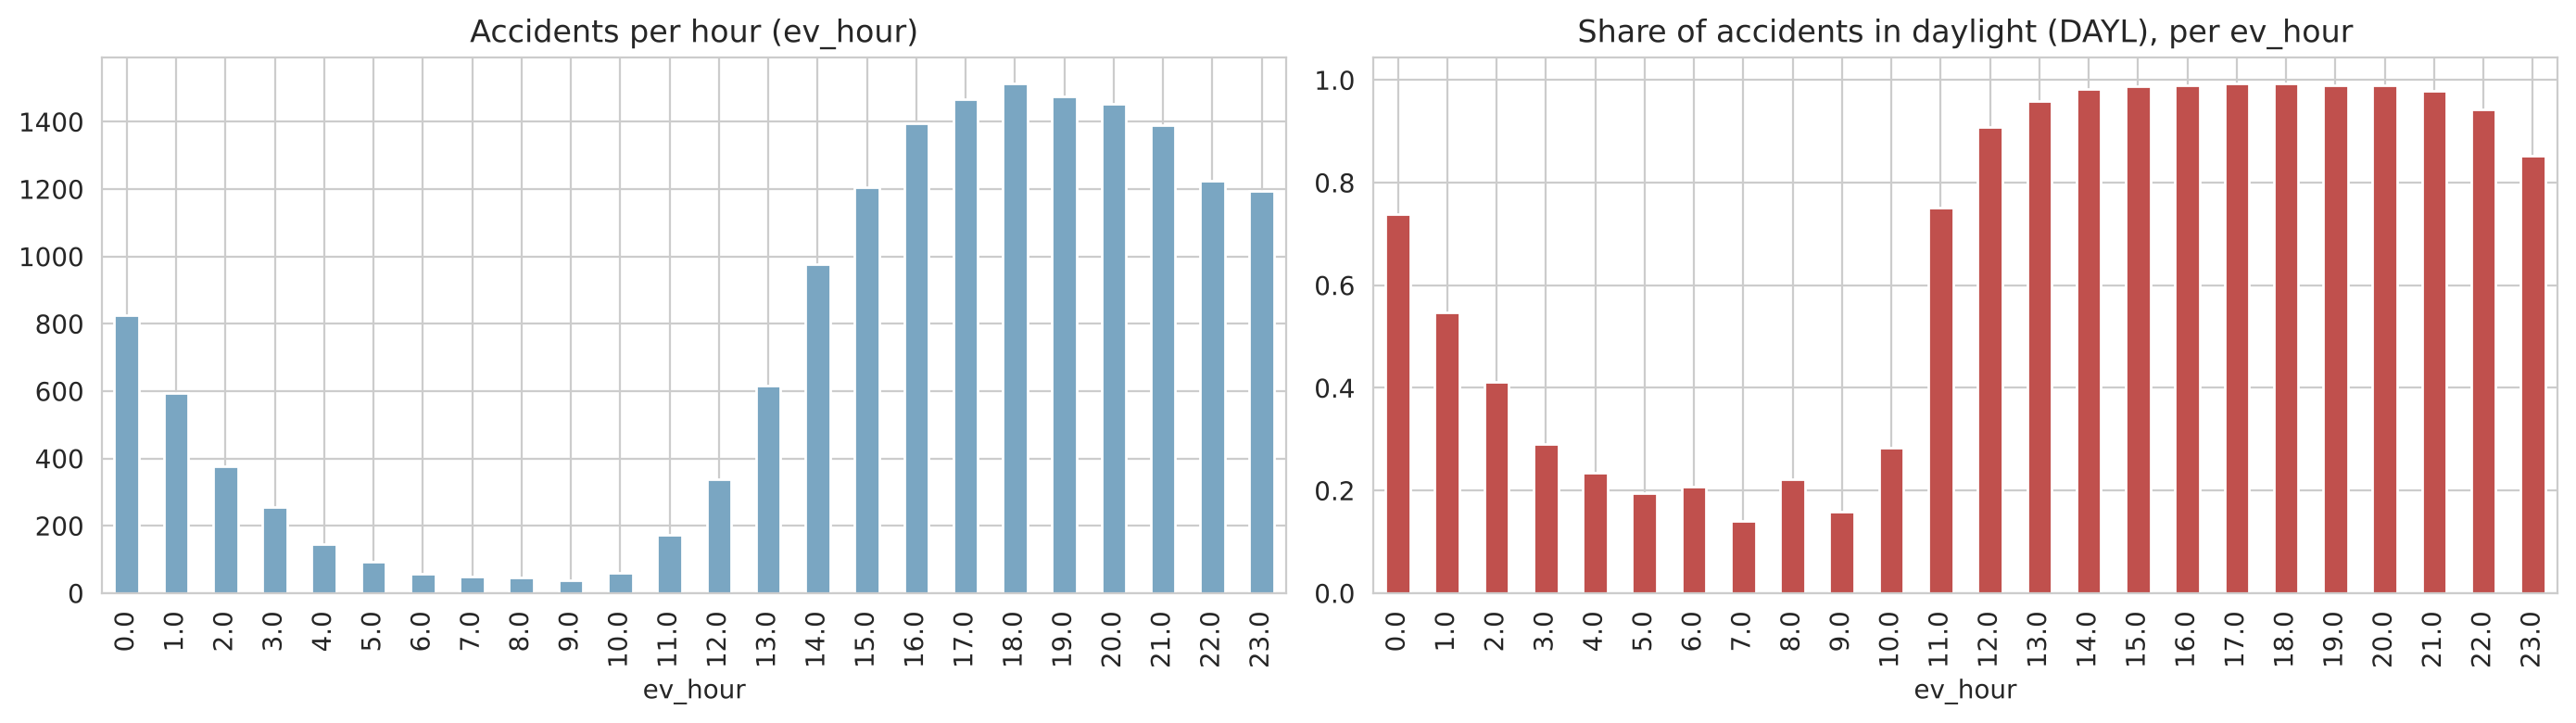

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
learn["ev_hour"].value_counts().sort_index().plot.bar(ax=axes[0], color="#7aa6c2")
axes[0].set_title("Accidents per hour (ev_hour)")

# share of 'daylight' accidents in each hour
day_share = learn.assign(daylight=learn["light_cond"].eq("DAYL")).groupby("ev_hour")["daylight"].mean()
day_share.plot.bar(ax=axes[1], color="#c0504d")
axes[1].set_title("Share of accidents in daylight (DAYL), per ev_hour")
plt.tight_layout()
plt.show()

The dictionary says `ev_hour` is the **local** hour, but the peak is at 17h-20h, **74% of the accidents at 0h (and 55% at 1h) happened in daylight**, and very few happen at 5h-10h, when it is mostly dark. This matches the pattern of **UTC time**, shifted by 5 to 8 hours from US local time. The hour is another instrument that may be lying: it is not wrong, just not what the dictionary says.

**Decision:** keep `ev_hour` as it is (we cannot convert it without the time zone), but rely on `light_cond` for day/night. Check its usefulness in feature selection.

## 6. Categorical features

In [23]:
for col in cat_cols:
    if col == "acft_make":
        continue
    print(f"{col} ({learn[col].nunique()} values):")
    print("   ", learn[col].value_counts(dropna=False).to_dict())

ev_country (1 values):
    {'USA': 16979}
ev_dow (7 values):
    {'Sa': 3234, 'Su': 2711, 'Fr': 2543, 'Th': 2243, 'We': 2164, 'Mo': 2083, 'Tu': 2001}
light_cond (7 values):
    {'DAYL': 15238, 'NITE': 839, 'DUSK': 394, 'NDRK': 314, 'DAWN': 115, 'NR': 32, nan: 26, 'NBRT': 21}
wx_cond_basic (3 values):
    {'VMC': 16121, 'IMC': 771, 'Unk': 68, nan: 19}
sky_cond_ceil (5 values):
    {'NONE': 10662, 'BKN': 2574, nan: 2002, 'OVC': 1597, 'UNK': 95, 'VV': 49}
sky_cond_nonceil (5 values):
    {'CLER': 9371, nan: 2821, 'FEW': 2284, 'SCAT': 2206, 'UNK': 157, 'OVCT': 140}
gust_ind (2 values):
    {'T': 10934, 'F': 6045}
far_part (15 values):
    {'091': 14964, '137': 841, '135': 547, '121': 299, 'PUBU': 199, '133': 90, '129': 15, 'NUSN': 5, 'NUSC': 4, 'UNK': 4, '091K': 4, '125': 2, '103': 2, nan: 1, '437': 1, '107': 1}
acft_category (19 values):
    {'AIR': 10899, 'air': 3655, 'HELI': 1285, 'heli': 382, 'GLI': 208, 'BALL': 105, 'WSFT': 98, 'GYRO': 90, 'gli': 64, 'PPAR': 53, 'wsft': 40, 'ball': 31

Findings:
- **Inconsistent spellings**: `acft_category` has `AIR` and `air`, `HELI` and `heli`, ...; `homebuilt` and `second_pilot` have `N`/`n` and `Y`/`y`. → **convert to upper case**.
- **Rare codes**: `far_part` has codes that are not in the dictionary (`103`, `107`, `437`) or appear 2-5 times; `type_fly` has 22 values, several with fewer than 30 rows; `eng_type` has `HR`, `GTFN`, `LR` once each. → unknown codes become `UNK`, and rare categories are grouped into an "infrequent" category during one-hot encoding (learned on training data only).
- Several columns have their own **unknown** codes (`UNK`, `Unk`, `NR`) besides the empty cells. We keep them as categories: "not reported" is information available at prediction time.

### 6.1. Aircraft manufacturer

In [24]:
make = learn["acft_make"].str.upper().str.strip()
print("distinct values:", learn["acft_make"].nunique(), "| after upper case:", make.nunique())
print("values that appear only once:", (make.value_counts() == 1).sum())
print()
print(make[make.str.contains("ROBINSON|CESSNA|AIR TRACTOR")].value_counts().head(12))

distinct values: 2914 | after upper case: 2914
values that appear only once: 2380

acft_make
CESSNA                         4248
ROBINSON HELICOPTER             194
AIR TRACTOR INC                 183
ROBINSON HELICOPTER COMPANY     155
ROBINSON                        143
AIR TRACTOR                     102
CESSNA AIRCRAFT CO               21
ROBINSON HELICOPTER CO           15
CESSNA ECTOR                      4
CESSNA/AIR REPAIR INC             2
ROBINSON MICHAEL E                2
AIR TRACTOR INC.                  2
Name: count, dtype: int64


`acft_make` has **2,914 different values**, and more than half of them appear only once. The same manufacturer is spelled in many ways (`ROBINSON`, `ROBINSON HELICOPTER`, `ROBINSON HELICOPTER COMPANY`, ...).
One-hot encoding it directly would create thousands of nearly empty columns.

**Decision:** keep only the **first word** of the name (`ROBINSON HELICOPTER COMPANY` → `ROBINSON`), and group the rare manufacturers into an infrequent category.

## 7. Relations with the target

### 7.1. Categorical features: fatal rate per category

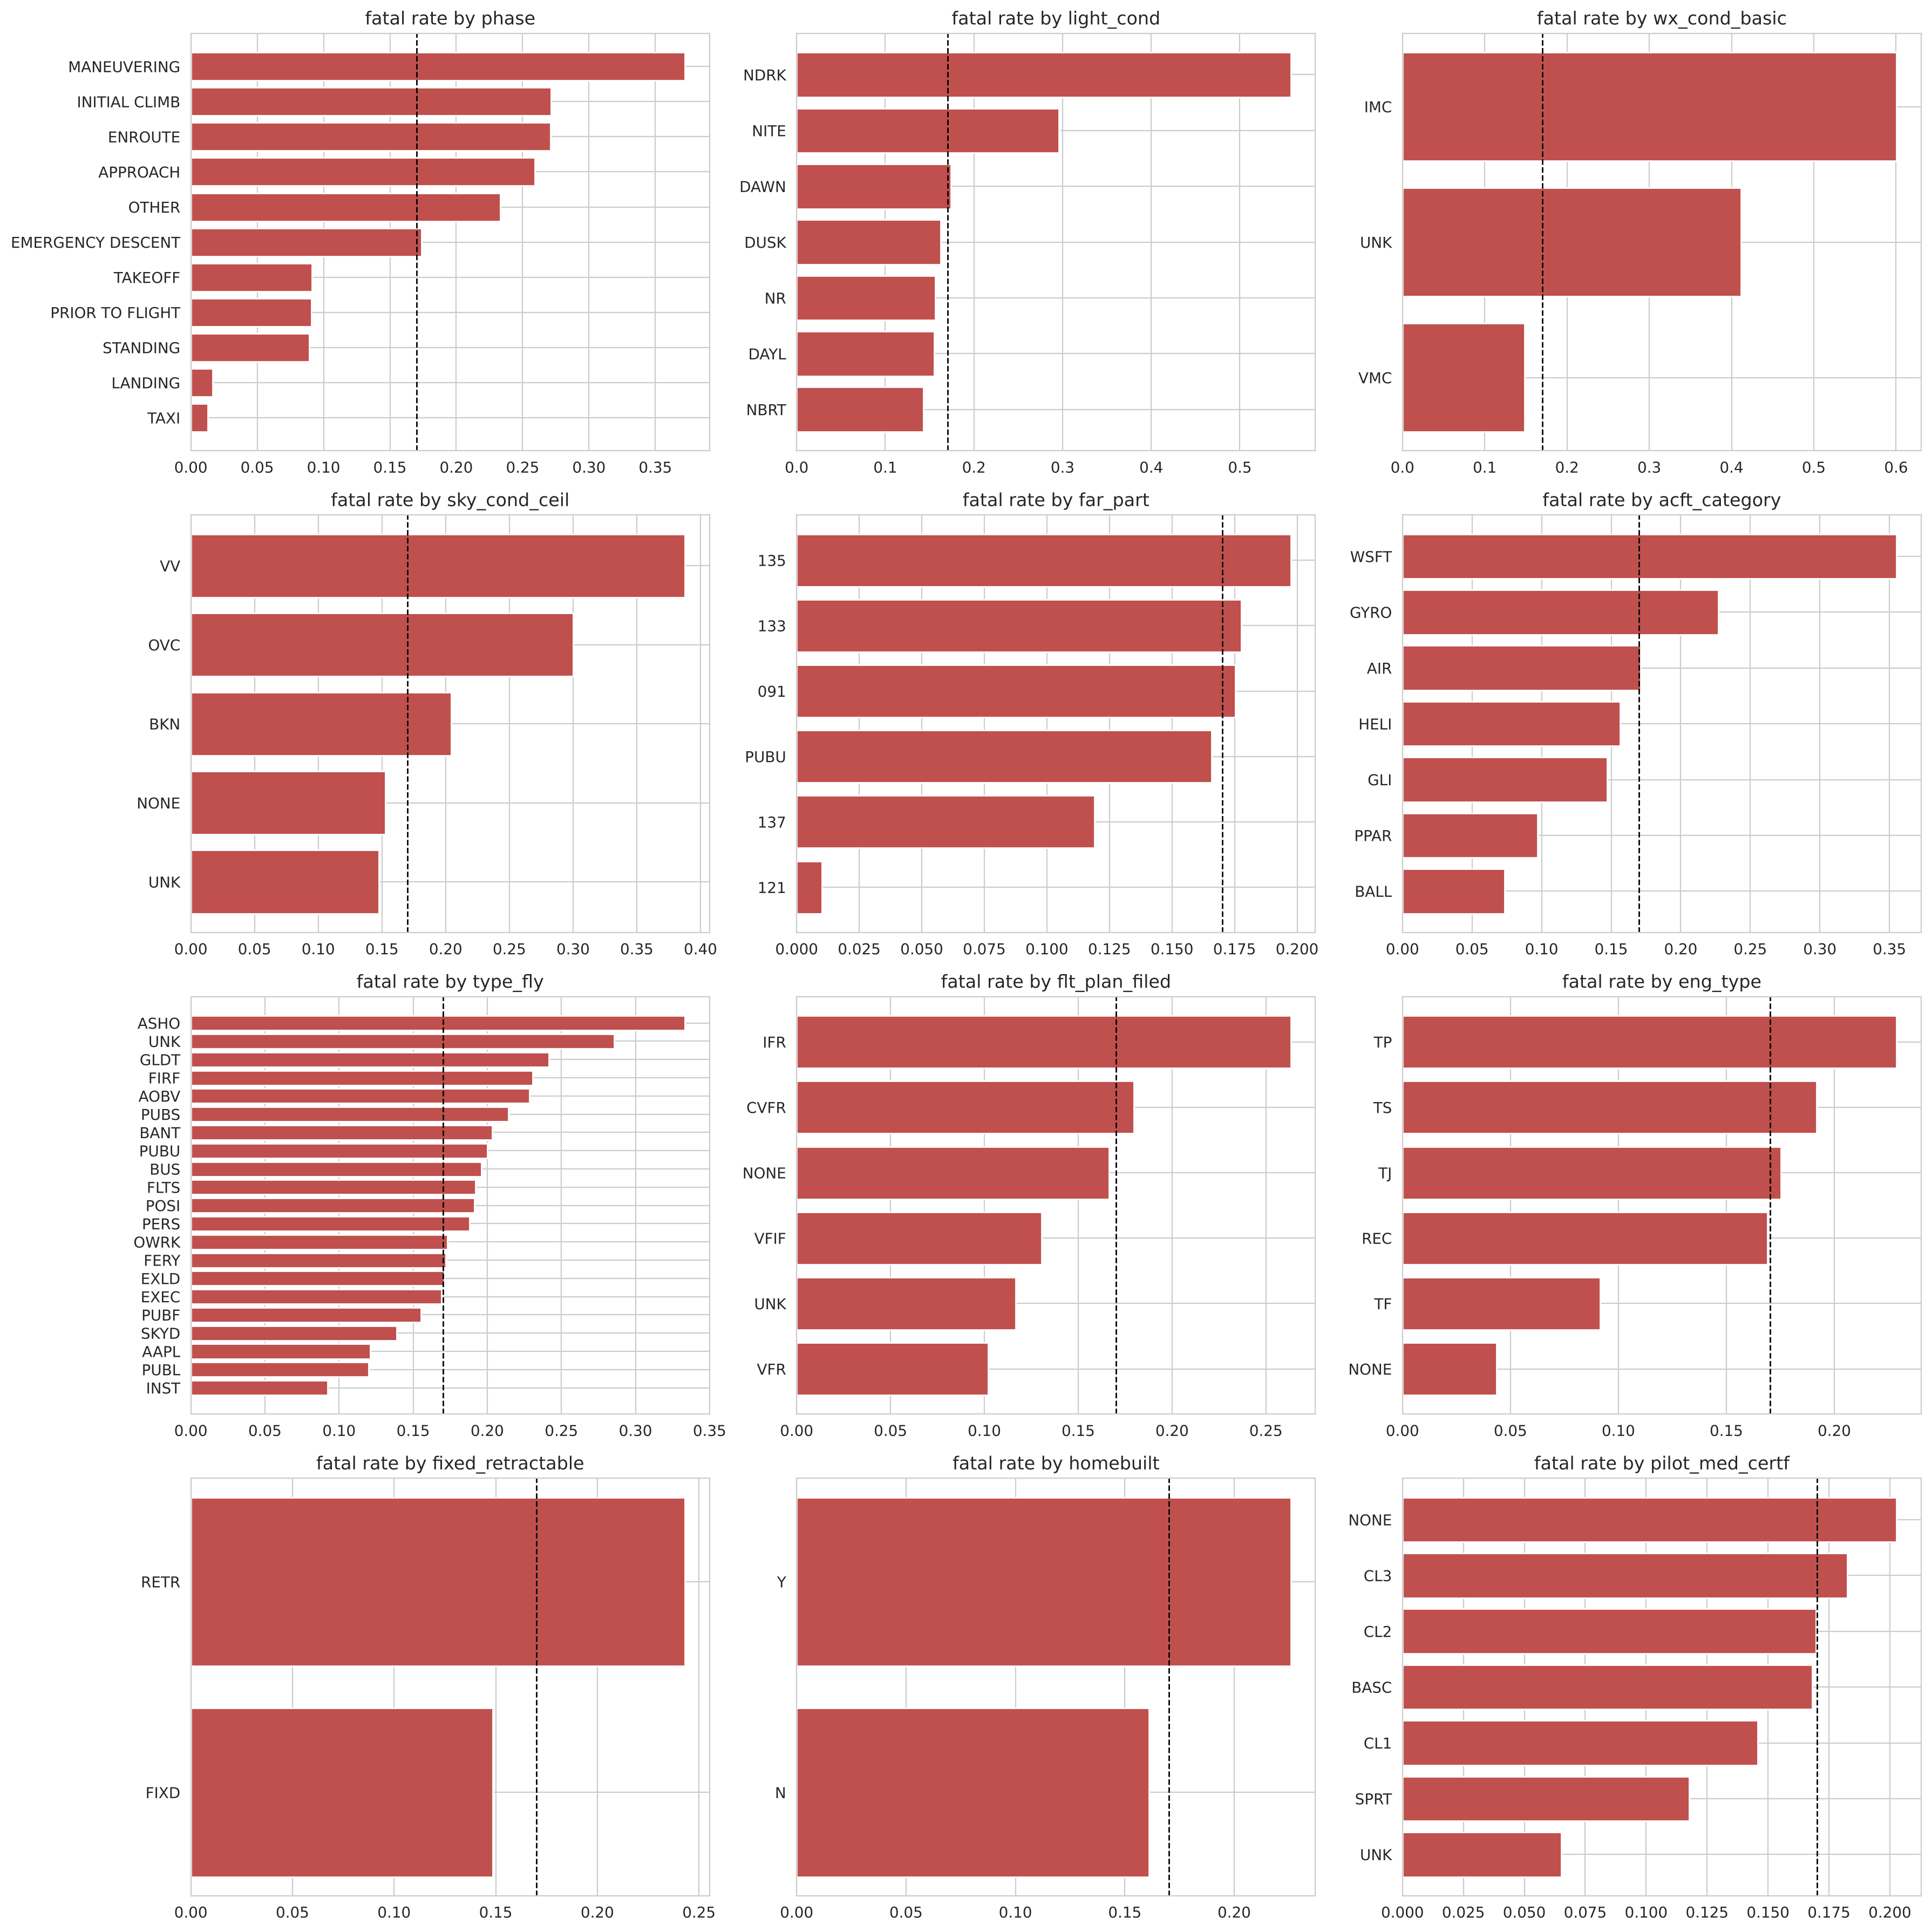

In [25]:
plot_cols = ["phase", "light_cond", "wx_cond_basic", "sky_cond_ceil", "far_part", "acft_category",
             "type_fly", "flt_plan_filed", "eng_type", "fixed_retractable", "homebuilt", "pilot_med_certf"]

fig, axes = plt.subplots(4, 3, figsize=(18, 18))
axes = axes.flatten()
for i, col in enumerate(plot_cols):
    s = learn[col].astype(str).str.upper()
    rate = learn.groupby(s)["fatal"].agg(["mean", "size"])
    rate = rate[rate["size"] >= 20].sort_values("mean")          # only categories with 20+ accidents
    axes[i].barh(rate.index, rate["mean"], color="#c0504d")
    axes[i].axvline(learn["fatal"].mean(), color="black", linestyle="--", linewidth=1)
    axes[i].set_title(f"fatal rate by {col}")
plt.tight_layout()
plt.show()

The dashed line is the global fatal rate (17%). The clearest patterns:
- **Phase of flight** is the strongest: accidents while **maneuvering (37%)**, en route, in initial climb or on approach (26-27%) are far more often fatal than accidents on **landing (2%)** or **taxi (1%)**, where speeds are low.
- **Weather and light**: under instrument conditions (**IMC, 60%**) and in dark nights (**NDRK, 56%**) the fatal rate is 3-4 times higher than in daylight VMC.
- **Ceiling**: overcast and obscured skies are more dangerous than no ceiling.
- **Regulation**: airline flights (Part 121) are almost never fatal (1%); general aviation (Part 91) is around 18%.
- **Aircraft**: retractable gear and homebuilt aircraft (faster or less standard) have higher rates; weight-shift aircraft also stand out.
- **Purpose**: instructional flights are safer (9%) than personal flights (19%).

In [26]:
# chi-square test of independence between each categorical feature and the target
rows = []
for col in cat_cols:
    if col == "ev_country":          # constant column: the test is not defined
        continue
    table = pd.crosstab(learn[col].astype(str).str.upper(), learn["fatal"])
    chi2, p, dof, _ = chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append([col, chi2, p, cramers_v])

pd.DataFrame(rows, columns=["feature", "chi2", "p-value", "Cramér's V"]).sort_values("Cramér's V", ascending=False).round(4)

,feature,chi2,p-value,Cramér's V
13,acft_make,3920.0325,0.0000,0.4805
18,phase,2164.4016,0.0000,0.3571
2,wx_cond_basic,1095.6329,0.0000,0.2542
1,light_cond,452.1878,0.0000,0.1633
3,sky_cond_ceil,236.0990,0.0000,0.1256
9,fixed_retractable,190.0199,0.0000,0.1058
10,type_fly,166.2397,0.0000,0.1013
11,flt_plan_filed,144.9667,0.0000,0.0931
15,carb_fuel_injection,110.8049,0.0000,0.0910
6,far_part,85.7174,0.0000,0.0711


The chi-square test confirms (with Cramér's V as the strength of the association) that `phase`, `wx_cond_basic`, `light_cond` and `sky_cond_ceil` are the most associated with fatality. At the other end, `ev_dow`, `gust_ind` and `second_pilot` are **not significant** (p > 0.05): the day of the week, the (unreliable) gust indicator and the presence of a second pilot do not seem to matter (`ev_country` was skipped: it is constant). Note that `acft_make` looks strong only because it has 2,914 categories, which inflates the statistic .
These tests are only exploratory here: in NB1 they are recomputed on the **training data only**, to avoid leakage in feature selection.

### 7.2. Numerical features by target

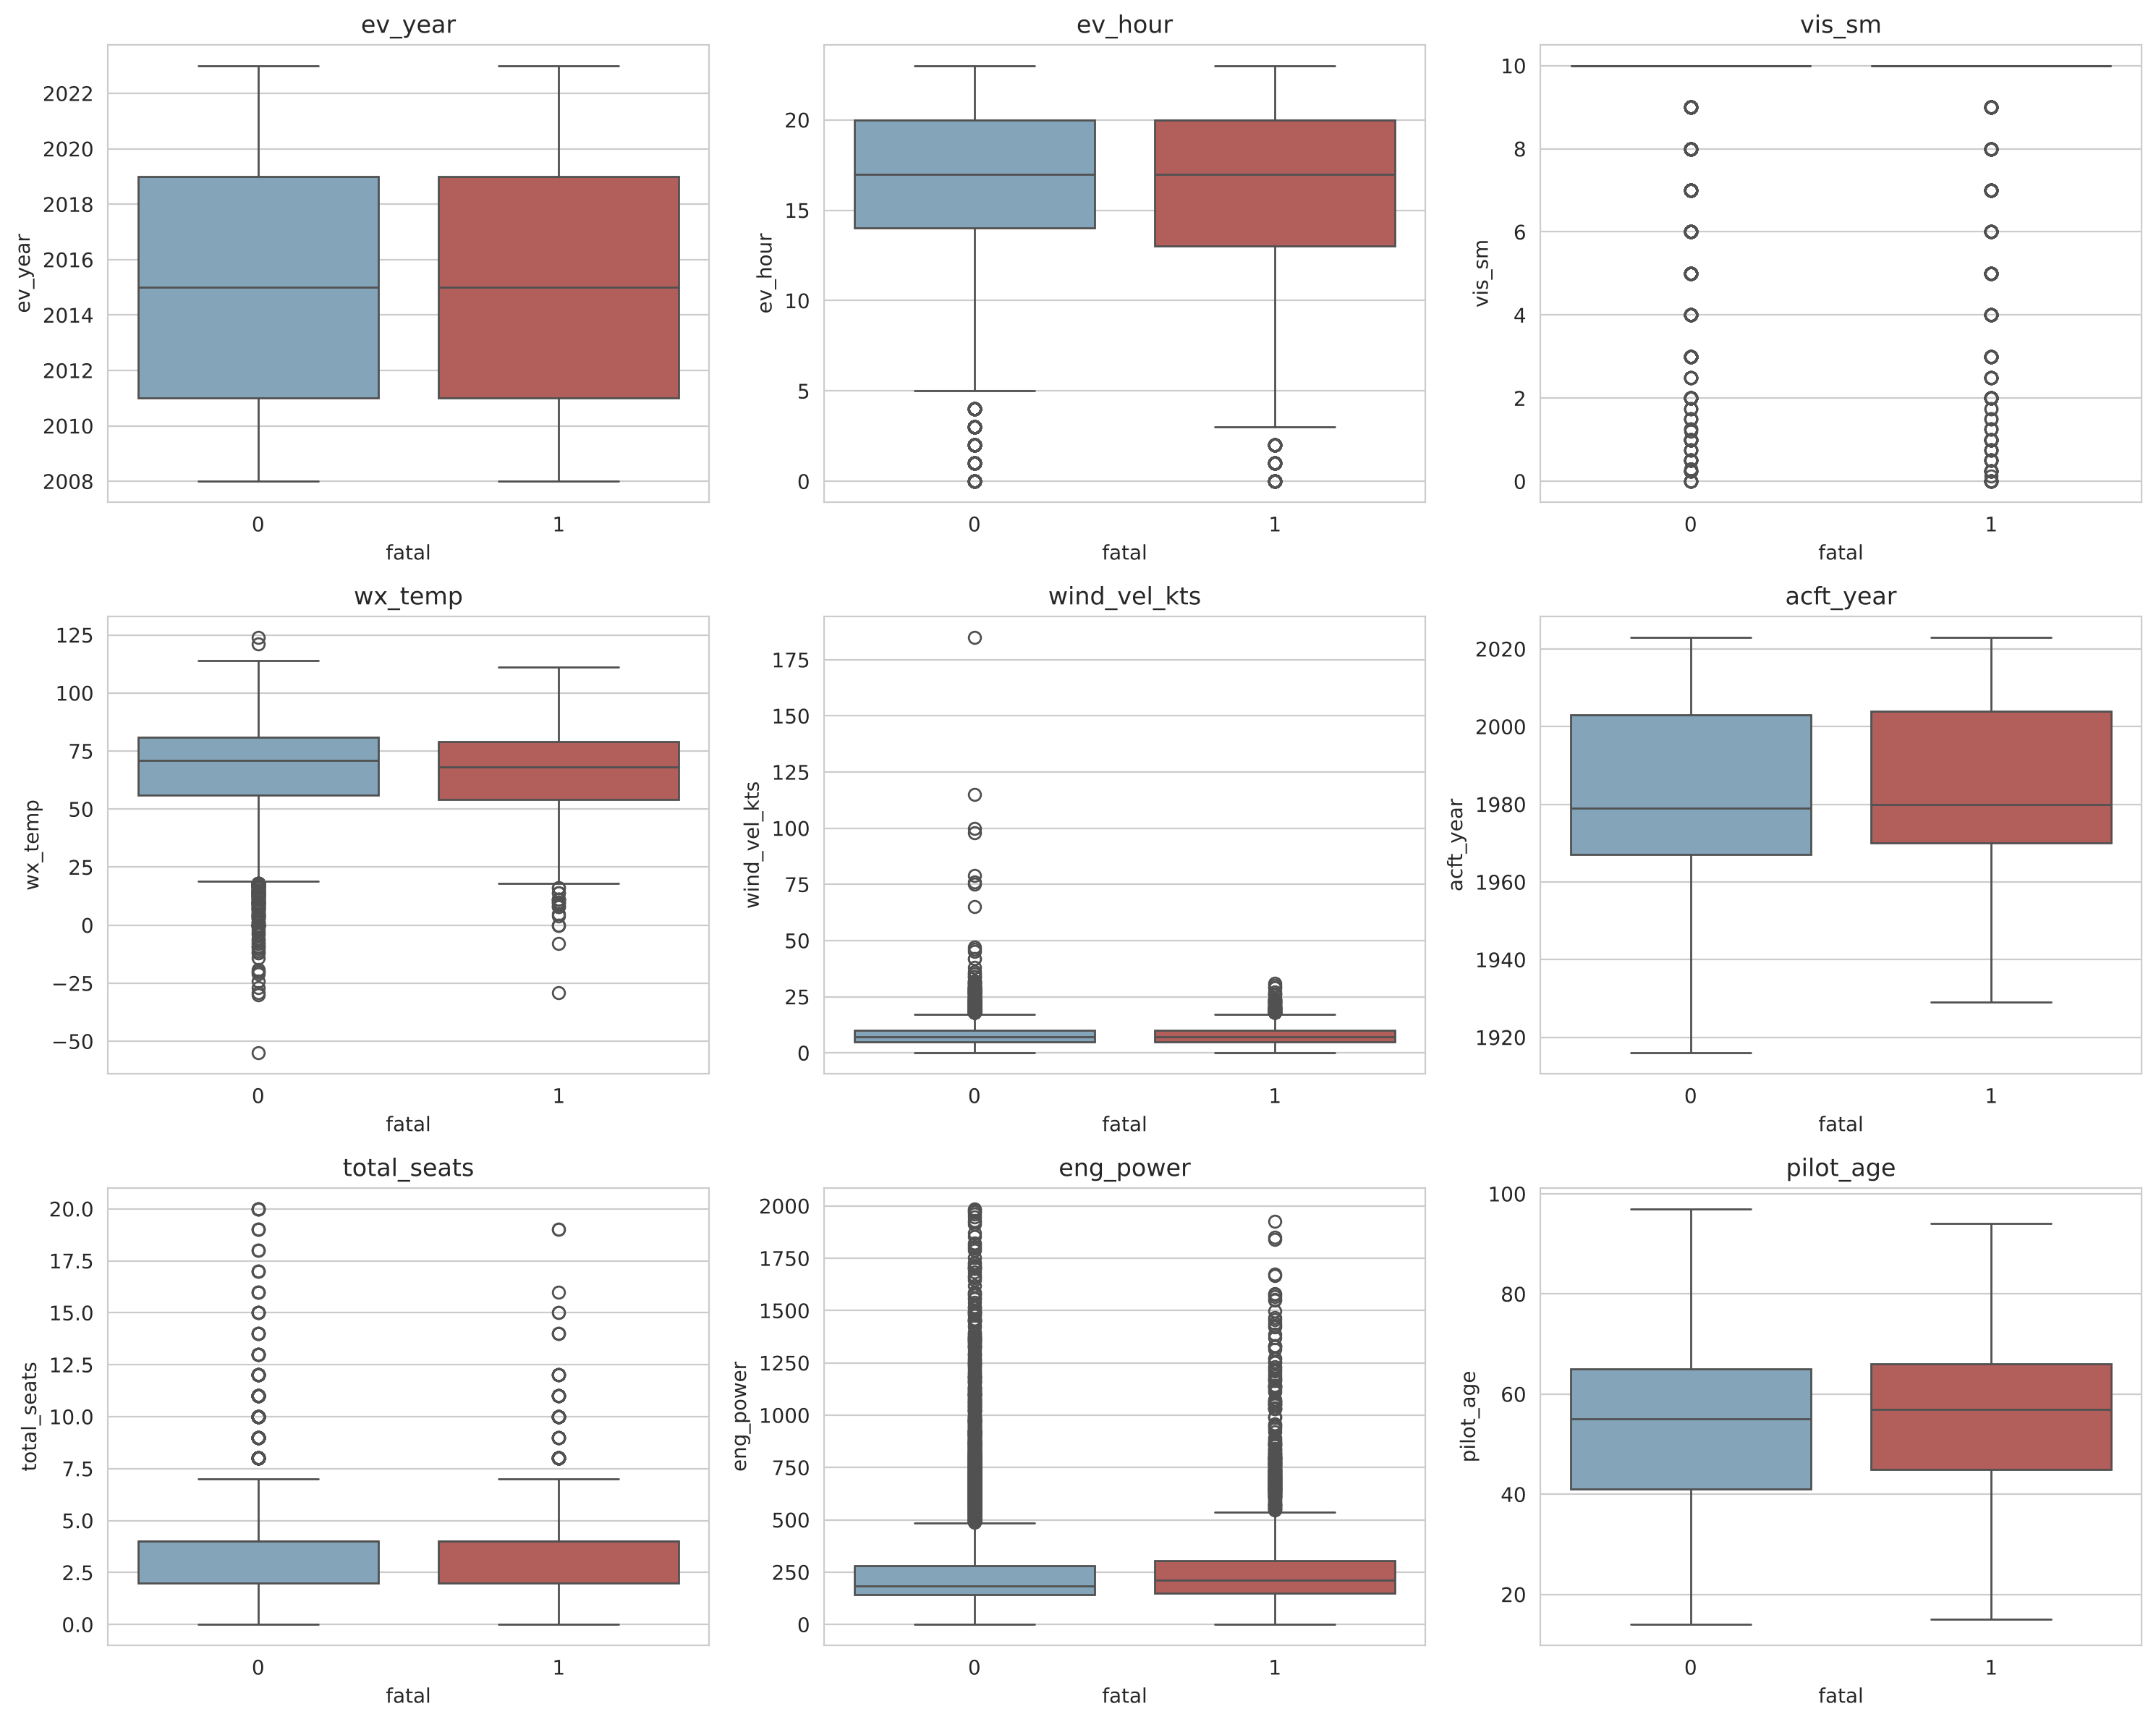

In [27]:
# temporary copy only for plotting: remove the obviously impossible values so the boxes are readable
view = learn.copy()
view.loc[view["wx_temp"].eq(0) & view["wx_dew_pt"].eq(0), ["wx_temp", "wx_dew_pt"]] = np.nan
view.loc[view["wx_temp"] > 130, "wx_temp"] = np.nan
view.loc[(view["acft_year"] < 1900) | (view["acft_year"] > view["ev_year"]), "acft_year"] = np.nan
view.loc[(view["pilot_age"] < 14) | (view["pilot_age"] > 100), "pilot_age"] = np.nan
view.loc[view["total_seats"] > 20, "total_seats"] = np.nan
view.loc[view["eng_type"].isin(["TF", "TJ"]) | (view["eng_power"] > 2000), "eng_power"] = np.nan
view["vis_sm"] = view["vis_sm"].clip(upper=10)

box_cols = ["ev_year", "ev_hour", "vis_sm", "wx_temp", "wind_vel_kts", "acft_year", "total_seats", "eng_power", "pilot_age"]
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.flatten()
for i, col in enumerate(box_cols):
    sns.boxplot(data=view, x="fatal", y=col, ax=axes[i], hue="fatal", palette=["#7aa6c2", "#c0504d"], legend=False)
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

The numerical features separate the classes much less than the categorical ones. Fatal accidents tend to involve **lower visibility**, slightly more powerful engines and slightly more seats, but the boxes overlap a lot. `ev_year`, `ev_hour`, `wx_temp` and `pilot_age` show almost no difference between classes.
→ Expect the categorical features (phase, weather, light, distance to airport) to carry most of the predictive power, and some numerical features to be dropped in feature selection.

## 8. Relations between features

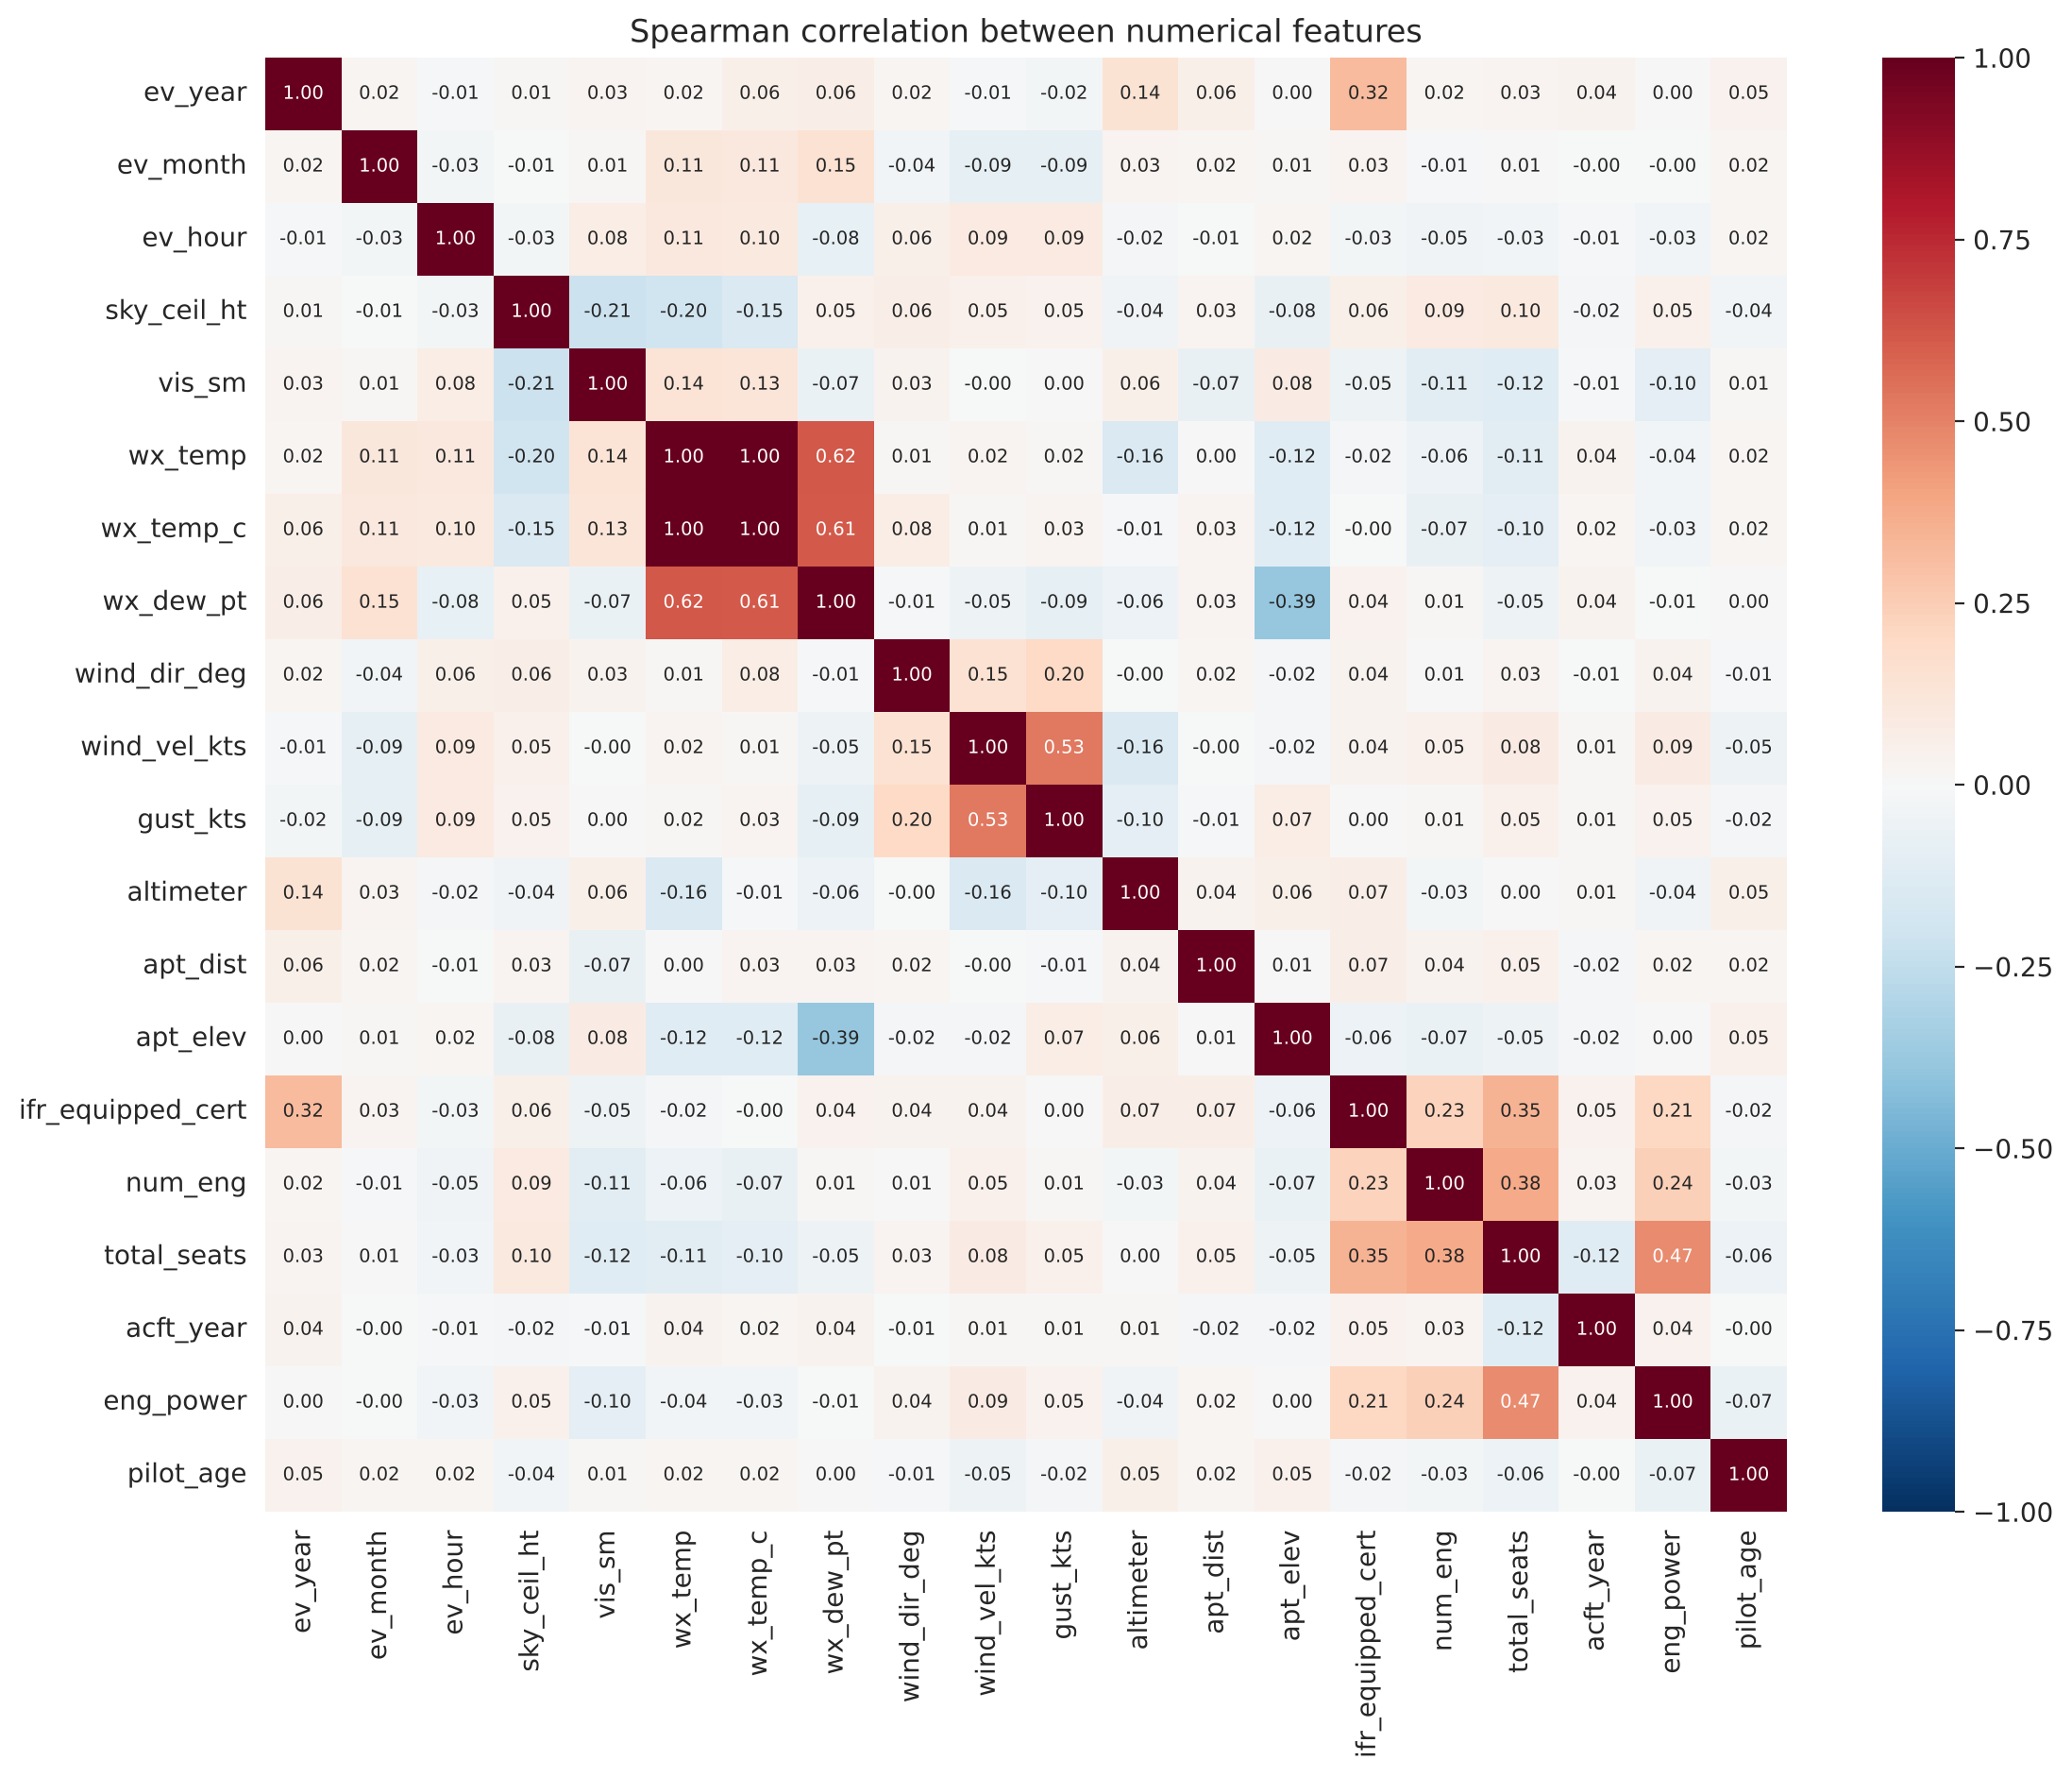

In [28]:
corr = view[num_cols].corr(method="spearman")

fig, ax = plt.subplots(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlation between numerical features")
plt.show()

In [29]:
# pairs with |rho| > 0.35
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
pairs[pairs.abs() > 0.35].sort_values(ascending=False).round(3)

wx_temp       wx_temp_c      1.000
              wx_dew_pt      0.618
wx_temp_c     wx_dew_pt      0.613
wind_vel_kts  gust_kts       0.526
total_seats   eng_power      0.472
num_eng       total_seats    0.377
wx_dew_pt     apt_elev      -0.385
dtype: float64

Spearman is used instead of Pearson because most features are skewed and full of outliers (it works on ranks). The plot uses the temporary copy from 7.2 (impossible values removed), so the correlations are not driven by errors.
- `wx_temp` and `wx_temp_c` are perfectly correlated (ρ = 1): confirms that one of them must go.
- `wx_temp` and `wx_dew_pt` are strongly correlated (ρ ≈ 0.66, as expected physically); their difference (spread) is a candidate feature.
- `wind_vel_kts` and `gust_kts` (ρ ≈ 0.53): gusts come with stronger wind.
- `total_seats`, `eng_power` and `num_eng` are moderately related (ρ ≈ 0.38-0.47): bigger aircraft have more seats and more power.
- Apart from the temperature pair, no correlation is high enough to call two features redundant.

→ Redundancy will be checked again in NB1, after cleaning, on the training data.

## 9. Summary: findings and decisions for NB1

All decisions below are applied in NB1. Rules that only look at **one row at a time** (fix a typo, set an impossible value to NaN) can be applied to any data. Anything **learned from the data** (medians, scaling, rare categories, feature selection) is fitted on the **training part only**.

| # | Finding | Decision for NB1 |
|---|---|---|
| 1 | Target imbalanced (17% fatal) | Stratified splits; F1 of class 1; `class_weight` and threshold tuning |
| 2 | `ev_country` is constant | Drop |
| 3 | `wx_temp_c` = `wx_temp` converted (ρ = 1) | Drop |
| 4 | `gust_ind` contradicts `gust_kts` | Drop; create `has_gust` from `gust_kts` |
| 5 | `wind_dir_deg`: 26% zeros, no relation with target | Drop |
| 6 | Temperature/dew point 0/0 = missing; values > 130 °F / 100 °F | Set to NaN; create `temp_dew_spread` |
| 7 | Altimeter: 0 = missing; ~3000 = missing decimal point | Divide by 100; keep 27-32 inHg, rest NaN |
| 8 | `vis_sm` above 10 | Clip at 10 |
| 9 | `eng_power` mixes HP and lbs of thrust | Keep HP for non-jets only (`eng_power_hp`); 0 and > 5000 → NaN |
| 10 | Impossible values: `pilot_age`, `total_seats`, `acft_year`, `apt_dist`, `apt_elev`, `sky_ceil_ht`, wind/gust > 100 kts | Set to NaN |
| 11 | `acft_year` 40% missing, year itself not meaningful | Create `acft_age` = `ev_year` − `acft_year` |
| 12 | Accidents away from the airport are 2-3x more often fatal | Create `off_airport` and `log_apt_dist` |
| 13 | Mixed upper/lower case in 3 columns | Convert to upper case |
| 14 | `acft_make` has 2,914 values | Keep first word; group rare values |
| 15 | Rare and undocumented codes (`far_part`, `type_fly`, `eng_type`) | Unknown → `UNK`; rare → infrequent category |
| 16 | Missingness is related to the target | Median imputation + missing indicators; `MISSING` category |
| 17 | `ev_hour` looks like UTC, not local time | Keep, rely on `light_cond`; check in feature selection |
| 18 | Phase, weather (IMC), night, ceiling are strongly associated with fatality | Expected key predictors; create `night`, `imc`, `has_ceiling` flags |

**Leakage check.** Every column describes the situation known one hour after the accident (where/when, weather, aircraft and pilot registration, flight plan, phase "as first reported"). None of them is a consequence of the outcome, so no column has to be dropped for leakage. We must still avoid *procedural* leakage in NB1 (fitting preprocessing or selection on validation/test data).